# Figures for the homodesmotic paper (single-column, 3.25 in)

All figures are 3.25 in wide so they fit one journal column: Figures 2–4 are stacked vertically, Figure 5 has larger structures, and structures use the ACS 1996 drawing style with subscripted groups (CH₃, H₃C).

Run the **Setup** cell once (it loads the data and the drawing helpers). Then run only the cell of the figure you want to change: edit its code (for example the figure height) and re-run that cell. Each figure is saved to `figures/` as a 600 dpi PNG and a vector PDF and shown below the cell. The width is set by `COL1` in the Setup cell.

Requirements: `pip install numpy matplotlib pillow rdkit jupyter`. Open this notebook from the folder that contains `data/`.

In [1]:
!pip install numpy matplotlib pillow rdkit

## Setup

In [2]:
"""Publication figures (notebook version) for the manuscript.  Needs data/benchmark_errors.csv,
data/scaling.csv and data/wildcard_libraries.csv next to this notebook.

Writes figures/*.png (600 dpi) and figures/*.pdf (vector).
"""
import csv
import io
import math
import os
import random
from collections import defaultdict

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8.5, "axes.titlesize": 8.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 7.5, "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 3, "ytick.major.size": 3, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "svg.fonttype": "none", "figure.dpi": 150,
})
# Okabe-Ito colour-blind-safe palette
COL = {"ID": "#E69F00", "HY": "#56B4E9", "HO": "#009E73"}
NAME = {"ID": "Isodesmic", "HY": "Hypohomodesmotic", "HO": "Homodesmotic"}
SCHEMES = ["ID", "HY", "HO"]
LEVELS = ["B3LYP/6-31+G(d)", "M06-2X/6-31+G(d)", "wB97X-D/def2-TZVP"]
LEVEL_LABEL = {"B3LYP/6-31+G(d)": "B3LYP/6-31+G(d)", "M06-2X/6-31+G(d)": "M06-2X/6-31+G(d)", "wB97X-D/def2-TZVP": "ωB97X-D/def2-TZVP"}
OUT = "figures"
COL1 = 3.25  # single-column width (in) of the journal; a few figures are drawn slightly narrower so that
             # their saved width, including labels outside the axes, stays within 3.25 in
ACS = 1 / 600  # in/px: structures drawn by mol_png print at the ACS 1996 size at this scale

os.makedirs(OUT, exist_ok=True)


def _find_arial():
    """Path of Arial (macOS, Windows, Linux), else its metric twin Liberation Sans, else Helvetica.
    RDKit needs the .ttf file itself to draw atom labels in the ACS font."""
    from matplotlib import font_manager as fm
    for fam in ("Arial", "Liberation Sans", "Helvetica"):
        try:
            p = fm.findfont(fm.FontProperties(family=fam), fallback_to_default=False)
            if p.lower().endswith(".ttf"):
                return p
        except ValueError:
            pass
    print("Arial not found: structure labels fall back to RDKit's built-in font")
    return ""


ARIAL = _find_arial()

# ----------------------------------------------------------------------------- data
rows = list(csv.DictReader(open("data/benchmark_errors.csv", encoding="utf-8")))
mol_order = []
for r in rows:
    if r["inchi"] not in mol_order:
        mol_order.append(r["inchi"])
CLASS = {r["inchi"]: r["class"] for r in rows}
SMILES = {r["inchi"]: r["smiles"] for r in rows}
# err[stage][level][scheme] -> array over molecules (in mol_order)
err = {st: {lv: {s: np.zeros(len(mol_order)) for s in SCHEMES} for lv in LEVELS} for st in ("opt", "sp")}
for r in rows:
    i = mol_order.index(r["inchi"])
    for s in SCHEMES:
        err[r["stage"]][r["geometry_level"]][s][i] = float(r[s])
is_str = np.array([CLASS[m] == "strained" for m in mol_order])
SUBSETS = {"unstrained": ~is_str, "strained": is_str, "all": np.ones(len(mol_order), bool)}


def pooled(stage, scheme, subset="all"):
    m = SUBSETS[subset]
    return np.concatenate([err[stage][lv][scheme][m] for lv in LEVELS])


rmse = lambda v: float(np.sqrt(np.mean(np.square(v))))
mae = lambda v: float(np.mean(np.abs(v)))


def boot_rmse(stage, scheme, subset, n=4000, seed=11):
    """95% CI of the pooled RMSE, resampling molecules (all three levels of a molecule kept together)."""
    rng = np.random.default_rng(seed)
    m = np.where(SUBSETS[subset])[0]
    stack = np.stack([err[stage][lv][scheme] for lv in LEVELS])  # 3 x mols
    vals = []
    for _ in range(n):
        idx = rng.choice(m, size=len(m), replace=True)
        vals.append(math.sqrt(np.mean(np.square(stack[:, idx]))))
    return np.percentile(vals, [2.5, 97.5])


def save(fig, name):
    w = fig.get_tightbbox().width + 2 * 0.04  # width as saved, including labels outside the axes
    if w > COL1 + 0.005 and not name.startswith("figS"):  # the SI figures may be full width
        print(f"WARNING: {name} is {w:.2f} in wide, more than one column ({COL1} in)")
    fig.savefig(f"{OUT}/{name}.png", dpi=600, bbox_inches="tight", pad_inches=0.04)
    fig.savefig(f"{OUT}/{name}.pdf", bbox_inches="tight", pad_inches=0.04, metadata={"CreationDate": None, "ModDate": None})
    plt.close(fig)
    print("wrote", name)


def panel(ax, letter, dx=-0.12, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")


def mol_png(smi, label_ends=True):
    """Structure in the ACS 1996 drawing style (bond length 14.4 pt, line width 0.6 pt, Arial 10 pt,
    double-bond spacing 18% of the bond length), rendered at 600 dpi: at scale ACS (in/px) it prints at
    the ACS size.  Terminal carbons are labelled CH3/CH2 with subscripts, as in ChemDraw's ACS style."""
    from rdkit.Chem import rdDepictor

    m = Chem.MolFromSmiles(smi)
    rdDepictor.Compute2DCoords(m)
    k = 600 / 72  # pixels per point
    d = rdMolDraw2D.MolDraw2DCairo(-1, -1)
    o = d.drawOptions()
    rdMolDraw2D.SetACS1996Mode(o, 1.5)
    o.fixedBondLength = 14.4 * k
    o.scalingFactor = 14.4 * k / 1.5
    o.bondLineWidth = 0.6 * k
    o.fixedFontSize = o.maxFontSize = int(10 * k)
    o.fontFile = ARIAL
    o.clearBackground = False
    if label_ends:  # CH3 / CH2 labels make tiny species (ethane, ethylene) readable; H3C when the bond leaves to the right
        pos = m.GetConformer().GetPositions()
        for a in m.GetAtoms():
            if a.GetSymbol() == "C" and a.GetDegree() == 1:
                n = a.GetTotalNumHs()
                h = "H" + (f"<sub>{n}</sub>" if n > 1 else "")
                nb = a.GetNeighbors()[0].GetIdx()
                o.atomLabels[a.GetIdx()] = h + "C" if pos[nb][0] > pos[a.GetIdx()][0] + 0.1 else "C" + h
    d.DrawMolecule(m)
    d.FinishDrawing()
    return np.array(Image.open(io.BytesIO(d.GetDrawingText())).convert("RGBA"))


def crop(img, pad=6):
    """Trim transparent margins so structures can be placed at a predictable size."""
    a = img[..., 3] > 0
    ys, xs = np.where(a)
    return img[max(ys.min() - pad, 0):ys.max() + pad, max(xs.min() - pad, 0):xs.max() + pad]


def common_scale(smiles, box_w, box_h, **kw):
    """Inches-per-pixel that fits every structure in the box, so all share one bond length."""
    out = []
    for smi in smiles:
        ih, iw = crop(mol_png(smi, **kw)).shape[:2]
        out.append(min(box_w / iw, box_h / ih))
    return min(out)


def place_mol(fig, smi, cx, cy, box_w, box_h, scale=None, **kw):
    """Draw a structure centred at (cx, cy) inches with correct aspect; `scale` (in/px) is shared across a figure."""
    img = crop(mol_png(smi, **kw))
    ih, iw = img.shape[:2]
    scale = scale or min(box_w / iw, box_h / ih)
    w, h = iw * scale, ih * scale
    W, H = fig.get_size_inches()
    ax = fig.add_axes([(cx - w / 2) / W, (cy - h / 2) / H, w / W, h / H])
    ax.imshow(img, aspect="equal", interpolation="lanczos")
    ax.axis("off")
    return ax


from IPython.display import Image as _Show, display


def show(name):
    display(_Show(filename=f"{OUT}/{name}.png", width=450))

## Figure 1: the three schemes on one molecule

wrote fig1_schemes


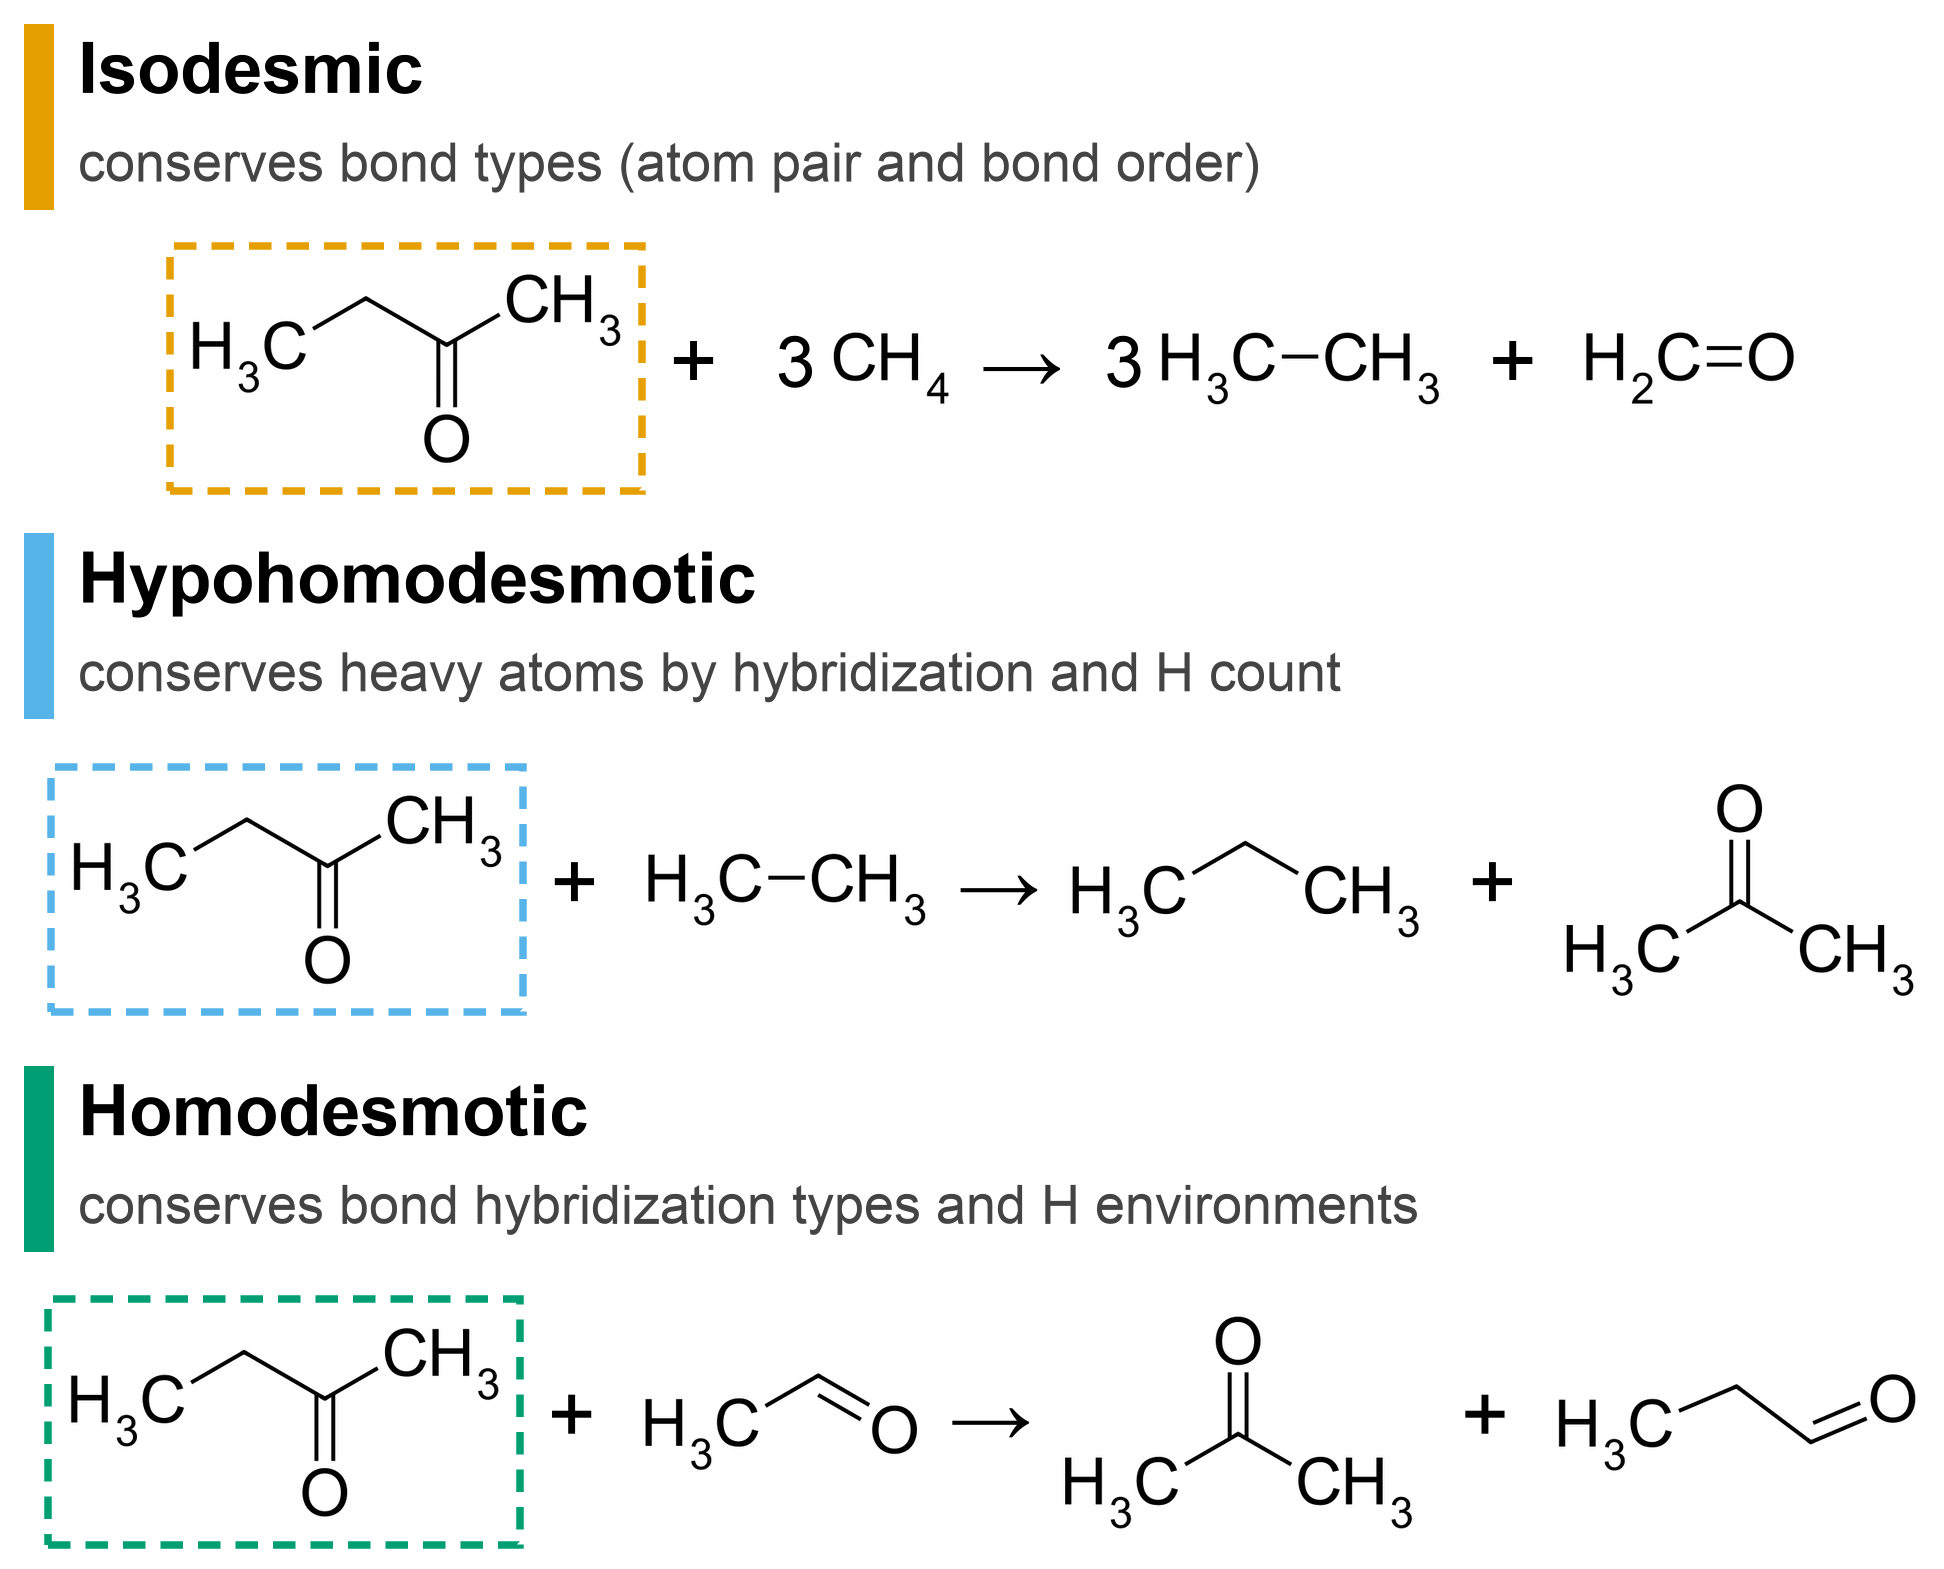

In [3]:
def fig1():
    # reactions for butan-2-one as generated by hfrpkg (coefficient, SMILES, is_target); fixed here so the
    # notebook runs without hfrpkg installed
    rxn = {
        "ID": ([(1, "CCC(C)=O", True), (3, "C", False)], [(3, "CC", False), (1, "C=O", False)]),
        "HY": ([(1, "CCC(C)=O", True), (1, "CC", False)], [(1, "CCC", False), (1, "CC(C)=O", False)]),
        "HO": ([(1, "CCC(C)=O", True), (1, "CC=O", False)], [(1, "CC(C)=O", False), (1, "CCC=O", False)]),
    }
    conserve = {"ID": "conserves bond types (atom pair and bond order)",
                "HY": "conserves heavy atoms by hybridization and H count",
                "HO": "conserves bond hybridization types and H environments"}
    W, opw, coefw, pad = COL1 - 0.02, 0.17, 0.11, 0.06
    imgs = {s: crop(mol_png(s)) for k in SCHEMES for side in rxn[k] for _, s, _ in side}

    def fixed(k):  # width of the operators and coefficients of one row
        L, R = rxn[k]
        return opw * (len(L) + len(R) - 1) + coefw * sum(c > 1 for c, _, _ in L + R) + pad * (len(L) + len(R))
    sc = min([ACS] + [(W - 0.08 - fixed(k)) / sum(imgs[s].shape[1] for _, s, _ in rxn[k][0] + rxn[k][1]) for k in SCHEMES])
    hdr = 0.40
    rowh = {k: hdr + max(imgs[s].shape[0] for _, s, _ in rxn[k][0] + rxn[k][1]) * sc + 0.12 for k in SCHEMES}
    H = sum(rowh.values()) + 0.04
    fig = plt.figure(figsize=(W, H))
    top = H - 0.02
    for k in SCHEMES:
        L, R = rxn[k]
        fig.add_artist(plt.Rectangle((0.0, (top - 0.34) / H), 0.05 / W, 0.31 / H, transform=fig.transFigure, color=COL[k], lw=0))
        fig.text(0.09 / W, (top - 0.115) / H, NAME[k], fontsize=8.5, fontweight="bold", va="center")
        fig.text(0.09 / W, (top - 0.27) / H, conserve[k], fontsize=6.5, va="center", ha="left", color="#444444")
        y0 = top - hdr - (rowh[k] - hdr - 0.12) / 2 - 0.04
        items = []
        for j, t in enumerate(L):
            items += [("mol",) + t] + ([("op", "+")] if j < len(L) - 1 else [])
        items.append(("op", "→"))
        for j, t in enumerate(R):
            items += [("mol",) + t] + ([("op", "+")] if j < len(R) - 1 else [])
        width = lambda it: opw if it[0] == "op" else imgs[it[2]].shape[1] * sc + pad + (coefw if it[1] > 1 else 0)
        x = (W - sum(width(it) for it in items)) / 2
        for it in items:
            if it[0] == "op":
                fig.text((x + opw / 2) / W, y0 / H, it[1], ha="center", va="center", fontsize=10)
            else:
                _, c, s_, tgt = it
                xm = x + pad / 2
                if c > 1:
                    fig.text((xm + coefw / 2) / W, y0 / H, str(c), fontsize=8.5, ha="center", va="center")
                    xm += coefw
                iw, ih = imgs[s_].shape[1] * sc, imgs[s_].shape[0] * sc
                place_mol(fig, s_, xm + iw / 2, y0, iw, ih, scale=sc)
                if tgt:
                    fig.add_artist(plt.Rectangle(((xm - 0.03) / W, (y0 - ih / 2 - 0.04) / H), (iw + 0.06) / W, (ih + 0.08) / H,
                                                 transform=fig.transFigure, fill=False, ec=COL[k], lw=0.9, ls=(0, (3, 2))))
            x += width(it)
        top -= rowh[k]
    save(fig, "fig1_schemes")
    return rxn


fig1()
show("fig1_schemes")

## Figure 2: error distributions (and Figure S1, before refinement)

wrote fig2_distributions
wrote figS1_distributions_preSPR


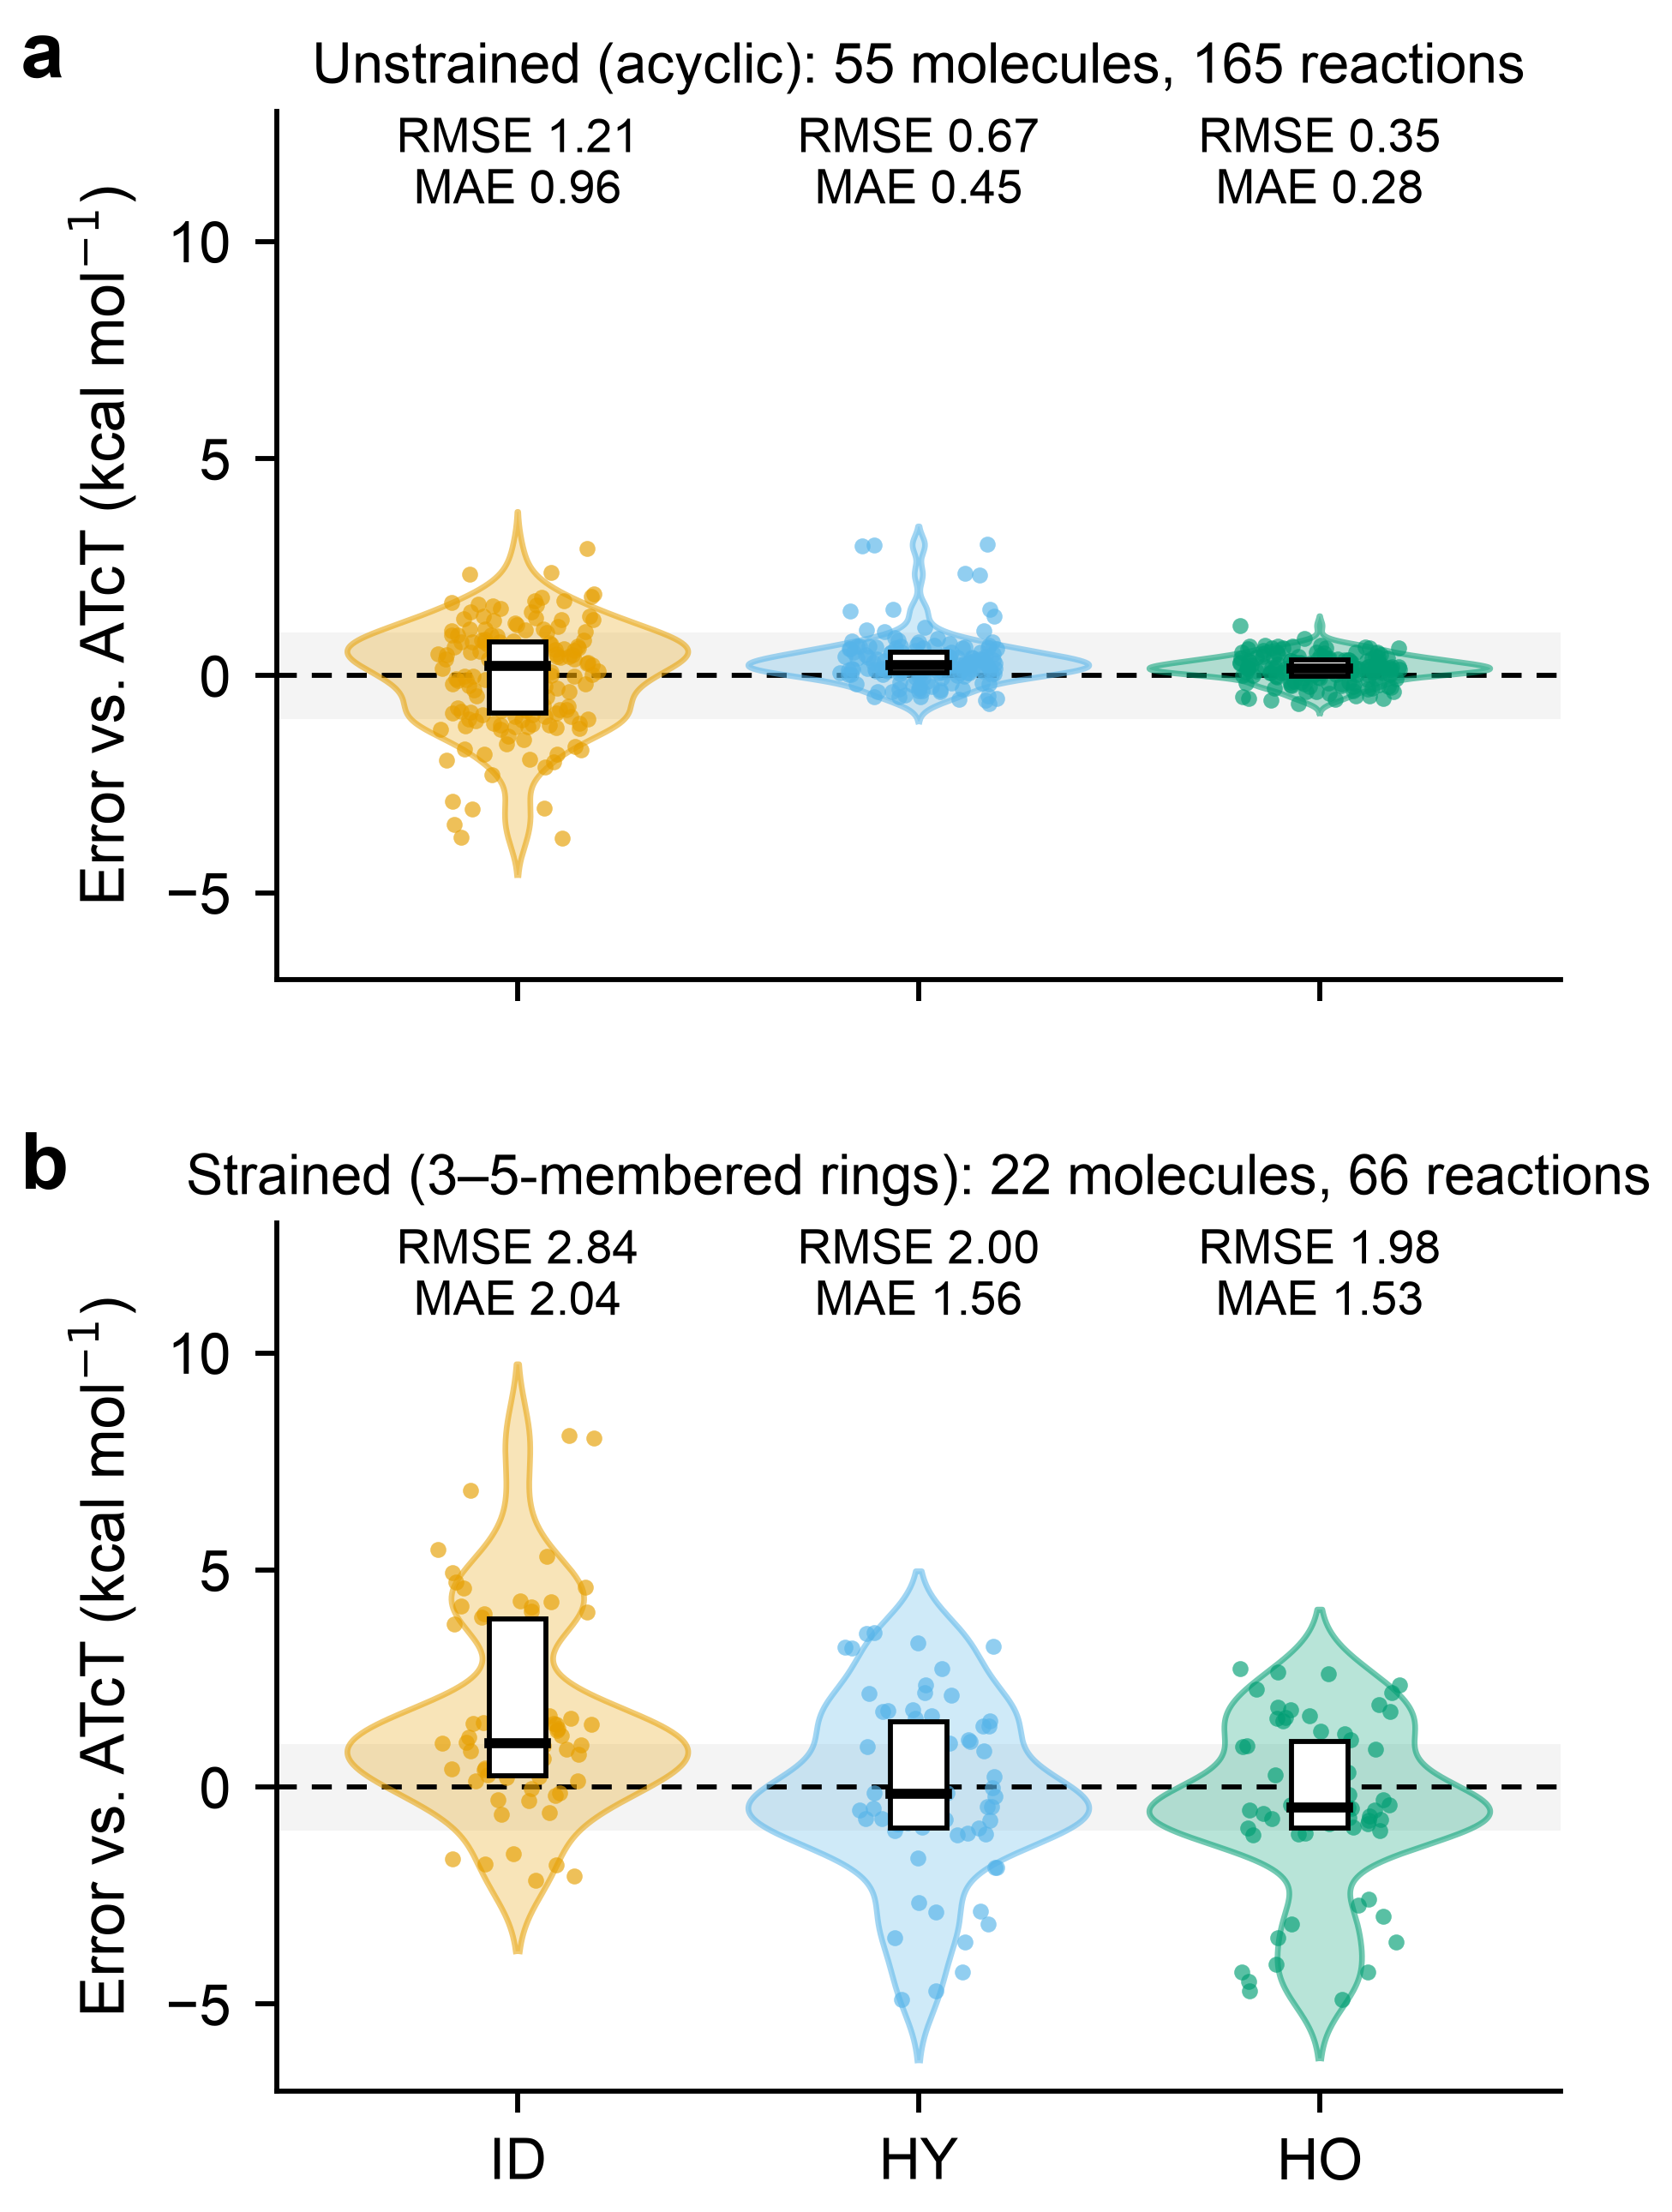

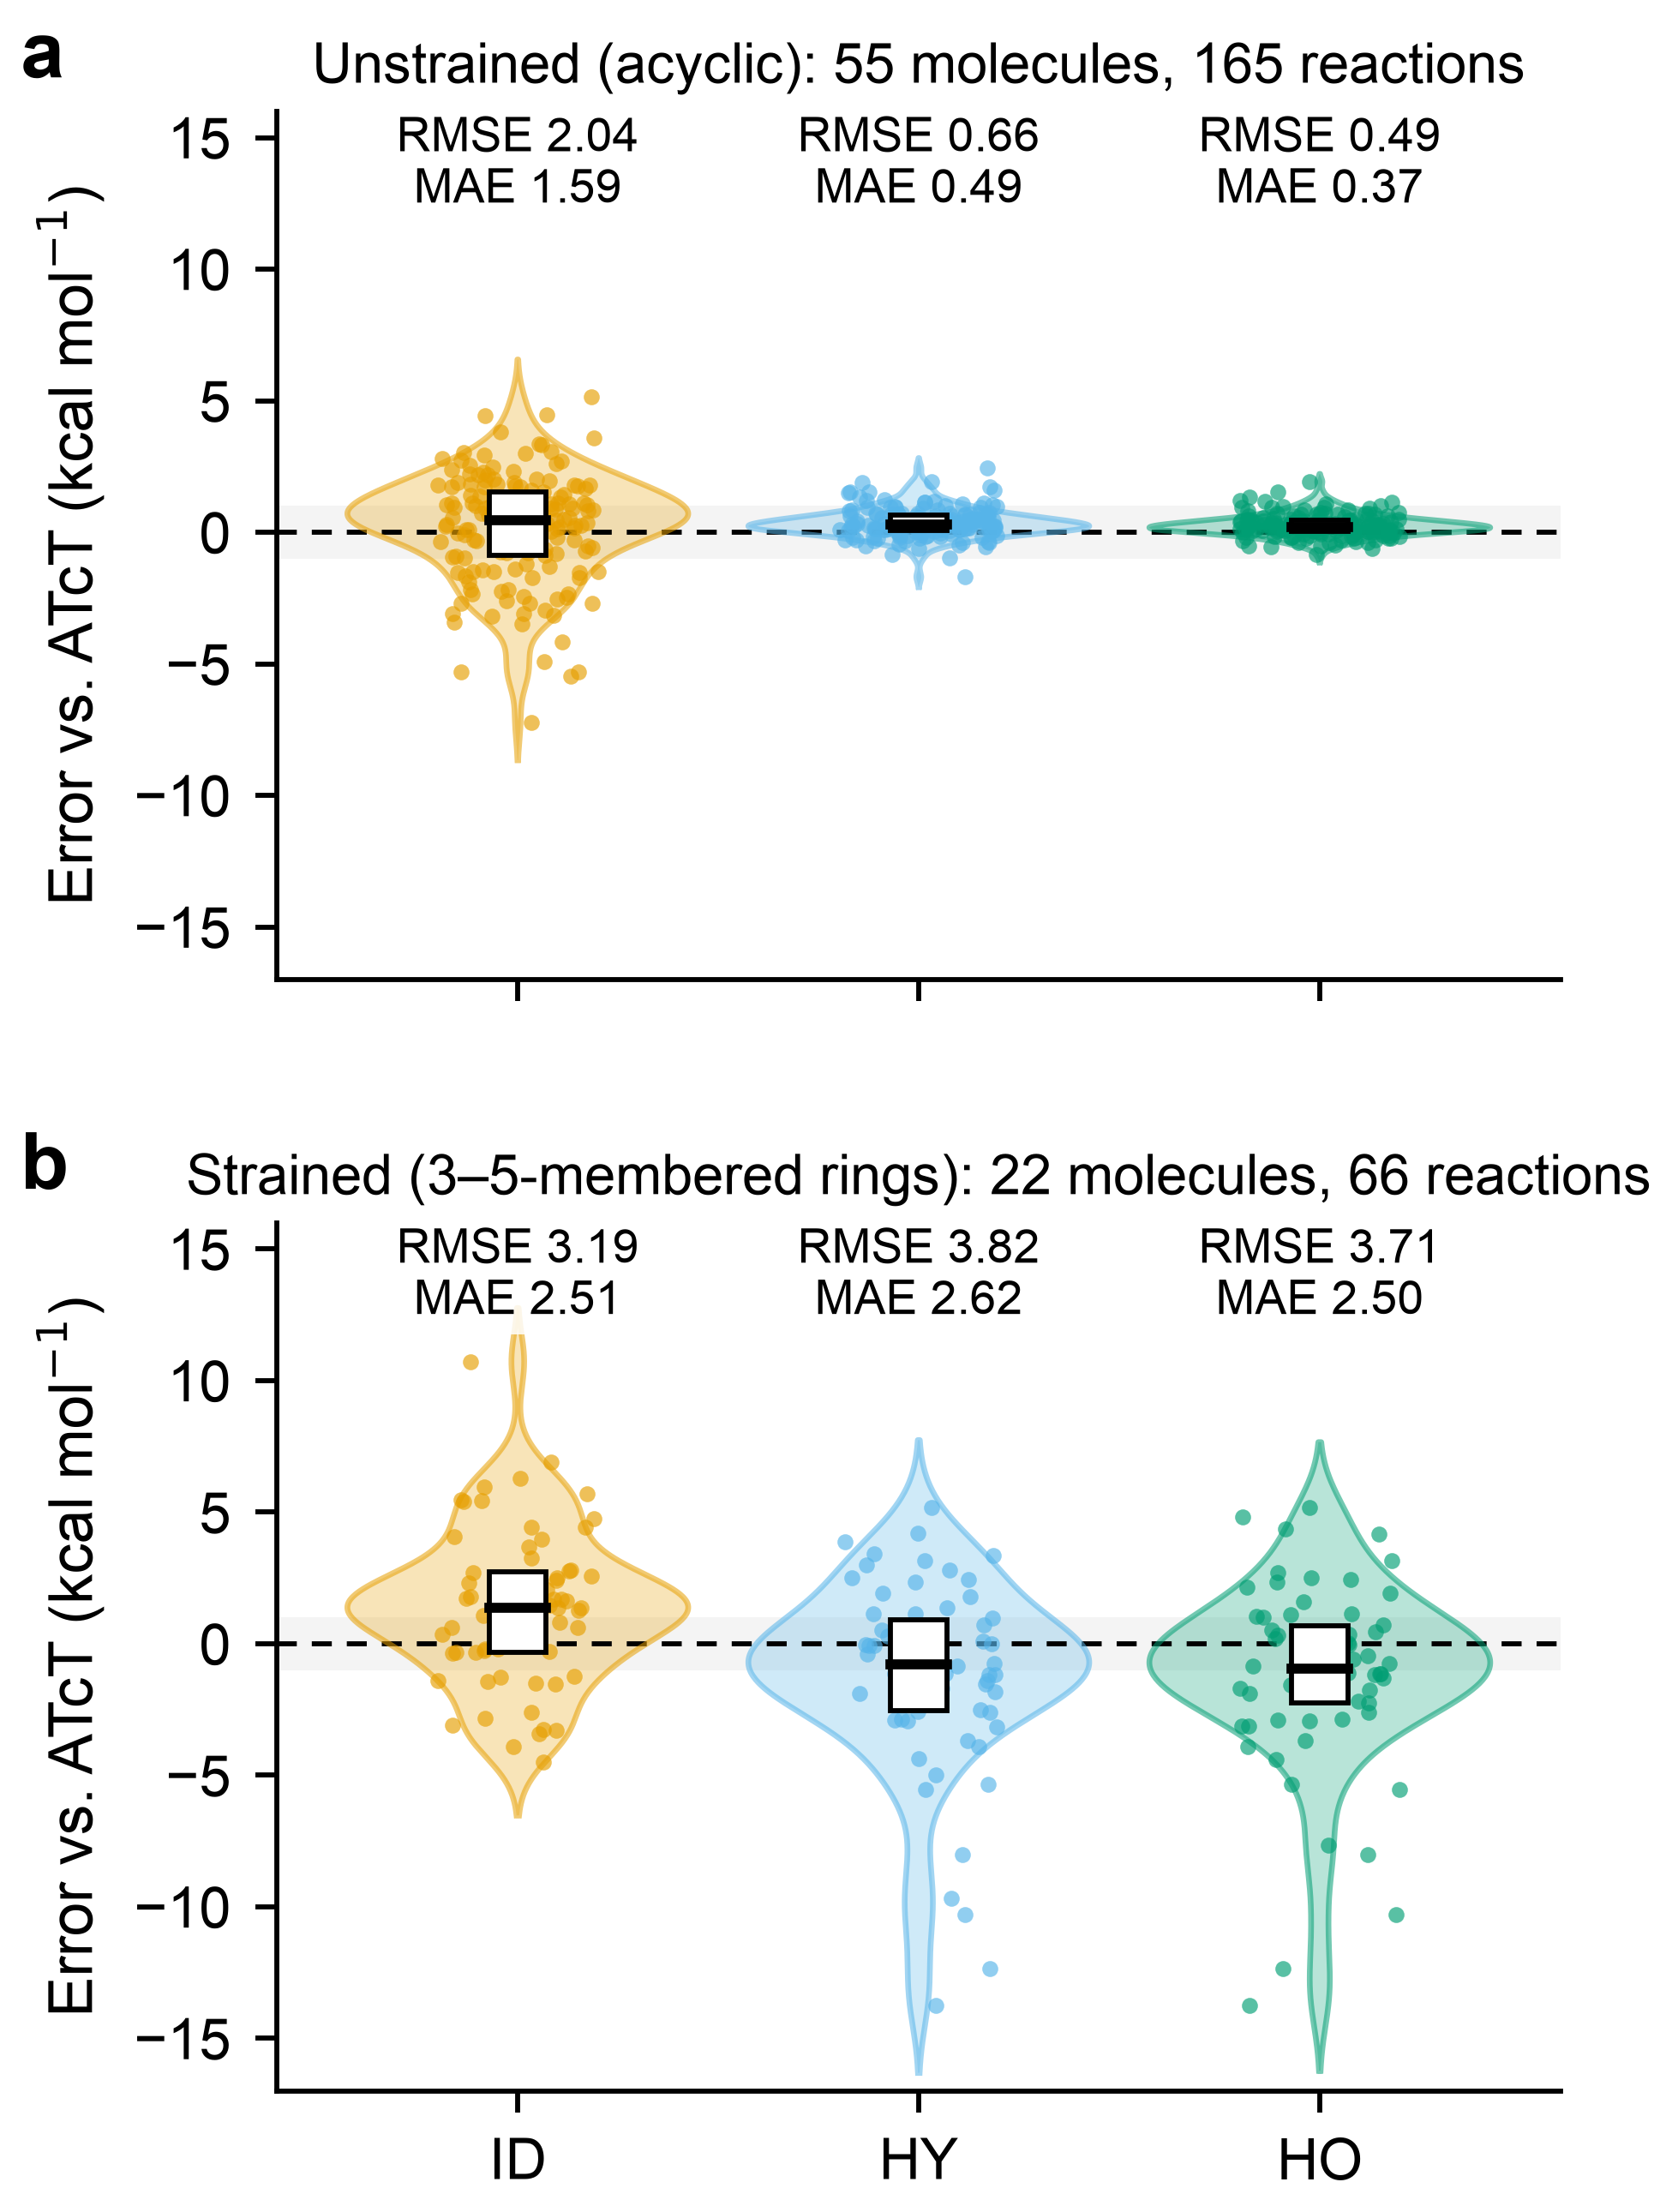

In [4]:
def kde_profile(v, factor=0.35, cut=2.0, n=400):
    """Gaussian KDE (bandwidth = factor x sample SD, as in matplotlib's violinplot) evaluated `cut`
    bandwidths beyond the data, so the violin tapers to a point instead of ending in a flat cap at the
    extreme observations.  Returns (y, density scaled to a maximum of 1)."""
    v = np.asarray(v, float)
    h = factor * v.std(ddof=1)
    y = np.linspace(v.min() - cut * h, v.max() + cut * h, n)
    d = np.exp(-0.5 * ((y[:, None] - v[None, :]) / h) ** 2).sum(axis=1)
    return y, d / d.max()


def dist_panel(ax, stage, subset, ylim):
    positions = np.arange(3)
    for p, s in zip(positions, SCHEMES):
        v = pooled(stage, s, subset)
        ky, kd = kde_profile(v)
        ax.fill_betweenx(ky, p - 0.425 * kd, p + 0.425 * kd, facecolor=COL[s], alpha=0.28, edgecolor="none", lw=0)
        ax.plot(np.r_[p - 0.425 * kd, (p + 0.425 * kd)[::-1]], np.r_[ky, ky[::-1]], color=COL[s], alpha=0.55, lw=0.8)
        rng = np.random.default_rng(3 + p)
        ax.scatter(p + rng.uniform(-0.2, 0.2, len(v)), v, s=5, color=COL[s], alpha=0.65, lw=0, zorder=3)
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        ax.add_patch(plt.Rectangle((p - 0.07, q1), 0.14, q3 - q1, fc="white", ec="black", lw=0.7, zorder=4))
        ax.plot([p - 0.07, p + 0.07], [med, med], color="black", lw=1.4, zorder=5)
    ax.axhline(0, color="black", lw=0.7, ls=(0, (4, 3)), zorder=1)
    ax.axhspan(-1, 1, color="#999999", alpha=0.10, lw=0, zorder=0)
    ax.set_xticks(positions)
    ax.set_xticklabels(SCHEMES)
    ax.set_ylim(*ylim)
    ax.set_xlim(-0.6, 2.6)
    for p, s in zip(positions, SCHEMES):
        v = pooled(stage, s, subset)
        ax.text(p, ylim[1] - 0.05, f"RMSE {rmse(v):.2f}\nMAE {mae(v):.2f}", ha="center", va="top", fontsize=6.6,
                bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.85))


def fig2(stage="sp", name="fig2_distributions", ylim=None):
    if ylim is None:  # derived from the data so that no point is ever clipped
        ext = [kde_profile(pooled(stage, s, sub))[0] for s in SCHEMES for sub in ("unstrained", "strained")]
        ylim = (np.floor(min(e.min() for e in ext) - 0.3), np.ceil(max(e.max() for e in ext) + 2.4))
    fig, axes = plt.subplots(2, 1, figsize=(COL1 - 0.03, 5.0), sharex=True, gridspec_kw=dict(hspace=0.28))
    for ax, subset, title in zip(axes, ("unstrained", "strained"), ("Unstrained (acyclic): {} molecules, {} reactions", "Strained (3–5-membered rings): {} molecules, {} reactions")):
        dist_panel(ax, stage, subset, ylim)
        n = int(SUBSETS[subset].sum())
        ax.set_title(title.format(n, 3 * n), fontsize=7.8, pad=4)
        ax.set_ylabel("Error vs. ATcT (kcal mol$^{-1}$)")
    panel(axes[0], "a", -0.20, 1.02)
    panel(axes[1], "b", -0.20, 1.02)
    save(fig, name)


fig2("sp", "fig2_distributions")
fig2("opt", "figS1_distributions_preSPR")
show("fig2_distributions")
show("figS1_distributions_preSPR")

## Figure 3: RMSE before/after SPR with bootstrap CIs

wrote fig3_rmse


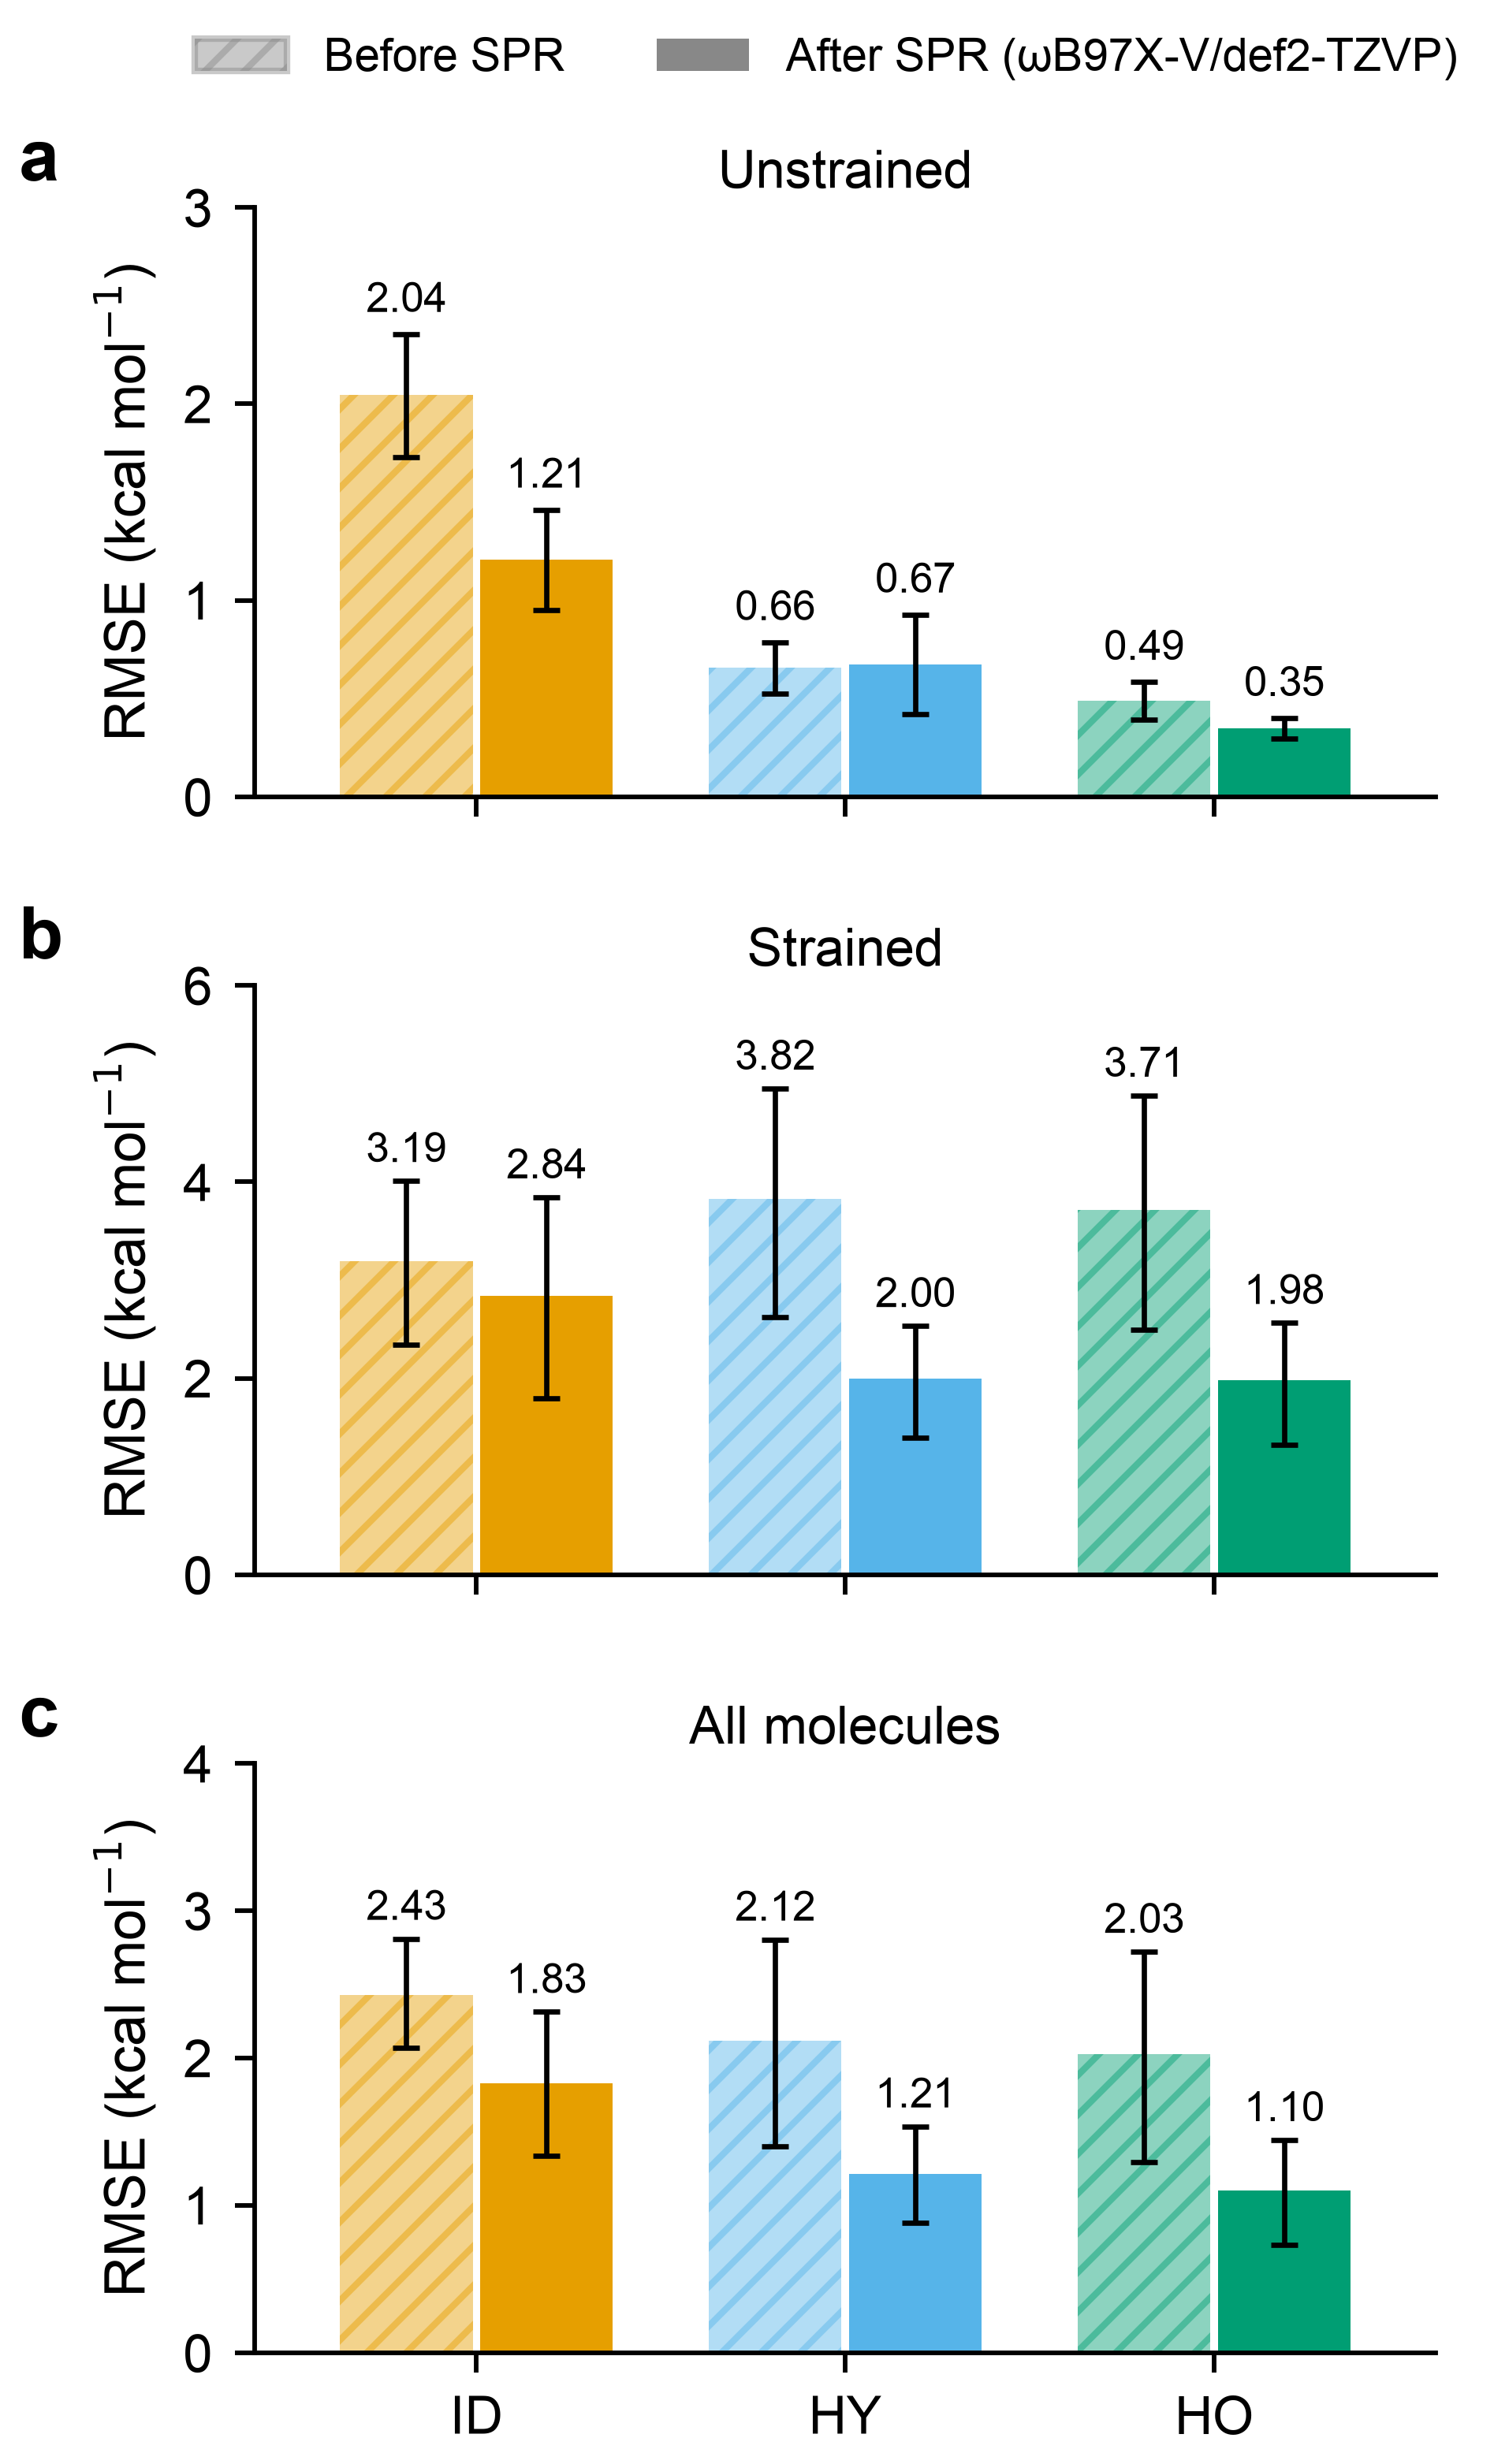

In [5]:
def fig3():
    fig, axes = plt.subplots(3, 1, figsize=(COL1 - 0.03, 5.6), sharex=True, gridspec_kw=dict(hspace=0.32))
    for ax, subset, title in zip(axes, ("unstrained", "strained", "all"), ("Unstrained", "Strained", "All molecules")):
        top = 0
        for j, s in enumerate(SCHEMES):
            for k, (stage, hatch, alpha) in enumerate((("opt", "////", 0.45), ("sp", None, 1.0))):
                v = pooled(stage, s, subset)
                lo, hi = boot_rmse(stage, s, subset)
                x = j + (k - 0.5) * 0.38
                ax.bar(x, rmse(v), width=0.36, color=COL[s], alpha=alpha, hatch=hatch, edgecolor="white" if hatch is None else COL[s], lw=0)
                ax.errorbar(x, rmse(v), yerr=[[rmse(v) - lo], [hi - rmse(v)]], color="black", lw=0.8, capsize=2, capthick=0.8)
                ax.text(x, hi + 0.06 * (5.2 if subset == "strained" else 3.4) / 3, f"{rmse(v):.2f}", ha="center", va="bottom", fontsize=6.4)
                top = max(top, hi)
        ax.set_xticks(range(3)); ax.set_xticklabels(SCHEMES)
        ax.set_title(title, fontsize=8, pad=3)
        ax.set_ylim(0, math.ceil(top * 1.12 + 0.3))
        ax.set_xlim(-0.6, 2.6)
        ax.set_ylabel("RMSE (kcal mol$^{-1}$)")
    for a_, l in zip(axes, "abc"):
        panel(a_, l, -0.20, 1.02)
    handles = [Patch(fc="#888888", alpha=0.45, hatch="////", ec="#888888", label="Before SPR"),
               Patch(fc="#888888", label="After SPR (ωB97X-V/def2-TZVP)")]
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=7)
    fig.subplots_adjust(top=0.92)
    save(fig, "fig3_rmse")


fig3()
show("fig3_rmse")

## Figure 4: geometry independence

wrote fig4_geometry


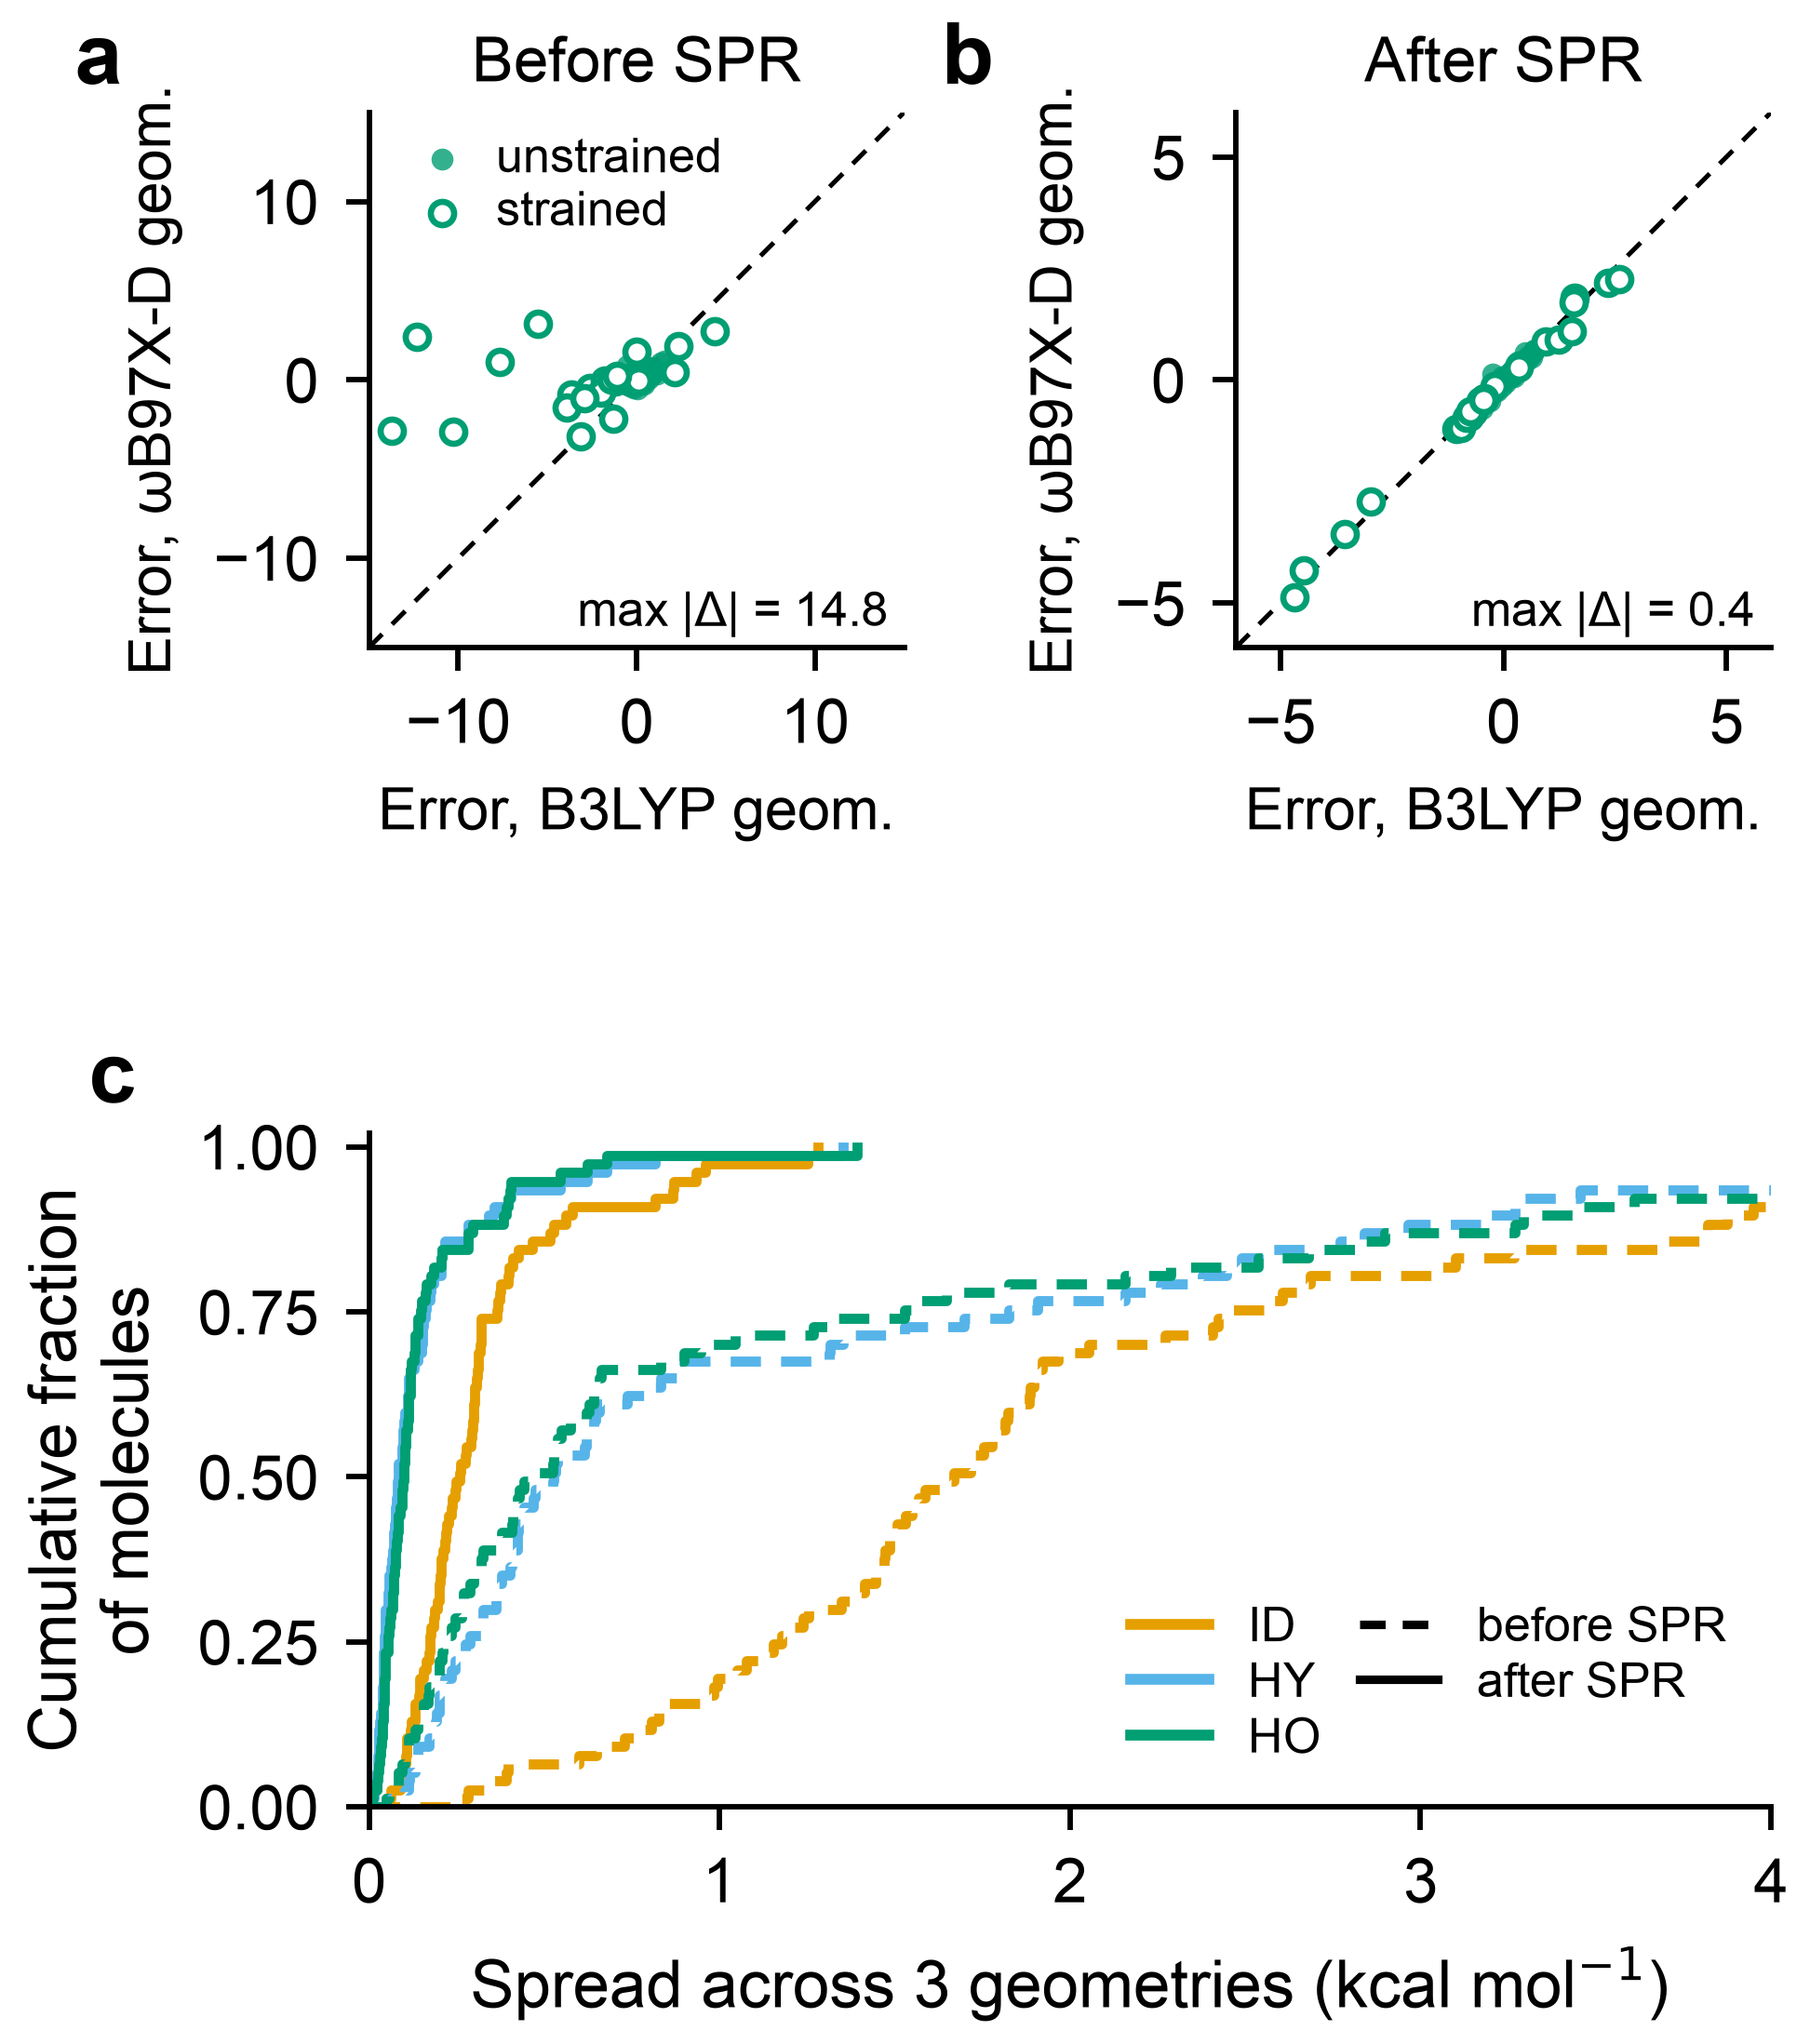

In [6]:
def fig4():
    fig = plt.figure(figsize=(COL1 - 0.15, 3.9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], wspace=0.62, hspace=0.62, left=0.17, right=0.98, top=0.93, bottom=0.12)
    lv_a, lv_b = LEVELS[0], LEVELS[2]
    for i, (stage, title) in enumerate((("opt", "Before SPR"), ("sp", "After SPR"))):
        ax = fig.add_subplot(gs[0, i])
        x = err[stage][lv_a]["HO"]; y = err[stage][lv_b]["HO"]
        lim = float(np.ceil(max(np.abs(x).max(), np.abs(y).max()) + 0.5))
        ax.plot([-lim, lim], [-lim, lim], color="black", lw=0.6, ls=(0, (4, 3)), zorder=1)
        ax.scatter(x[~is_str], y[~is_str], s=8, color=COL["HO"], lw=0, alpha=0.8, label="unstrained", zorder=3)
        ax.scatter(x[is_str], y[is_str], s=9, color="white", edgecolor=COL["HO"], lw=0.8, label="strained", zorder=3)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        ax.set_title(title, fontsize=8, pad=4)
        ax.set_xlabel("Error, B3LYP geom.", fontsize=7.5)
        ax.set_ylabel("Error, ωB97X-D geom.", fontsize=7.5)
        if i == 0:
            ax.legend(frameon=False, loc="upper left", handletextpad=0.1, borderpad=0, labelspacing=0.15, fontsize=6.3)
        ax.text(0.97, 0.04, f"max |Δ| = {np.max(np.abs(x - y)):.1f}", transform=ax.transAxes, ha="right", fontsize=6.2)
        panel(ax, "ab"[i], -0.55, 1.02)
    ax = fig.add_subplot(gs[1, :])
    for s in SCHEMES:
        for stage, ls in (("opt", (0, (3, 2))), ("sp", "-")):
            stack = np.array([err[stage][lv][s] for lv in LEVELS])
            xs = np.sort(stack.max(0) - stack.min(0))
            ax.step(np.r_[0, xs], np.r_[0, np.arange(1, len(xs) + 1) / len(xs)], where="post", color=COL[s], ls=ls, lw=1.3)
    ax.set_xlim(0, 4)
    ax.set_xlabel("Spread across 3 geometries (kcal mol$^{-1}$)")
    ax.set_ylabel("Cumulative fraction\nof molecules")
    ax.set_ylim(0, 1.02)
    h = [Line2D([], [], color=COL[s], lw=1.4, label=s) for s in SCHEMES]
    h += [Line2D([], [], color="black", lw=1.1, ls=(0, (3, 2)), label="before SPR"), Line2D([], [], color="black", lw=1.1, label="after SPR")]
    ax.legend(handles=h, frameon=False, loc="lower right", handlelength=1.6, labelspacing=0.2, fontsize=6.3, ncol=2, columnspacing=0.8)
    panel(ax, "c", -0.20, 1.02)
    save(fig, "fig4_geometry")


fig4()
show("fig4_geometry")

## Figure 5: strained molecules

wrote fig5_strained


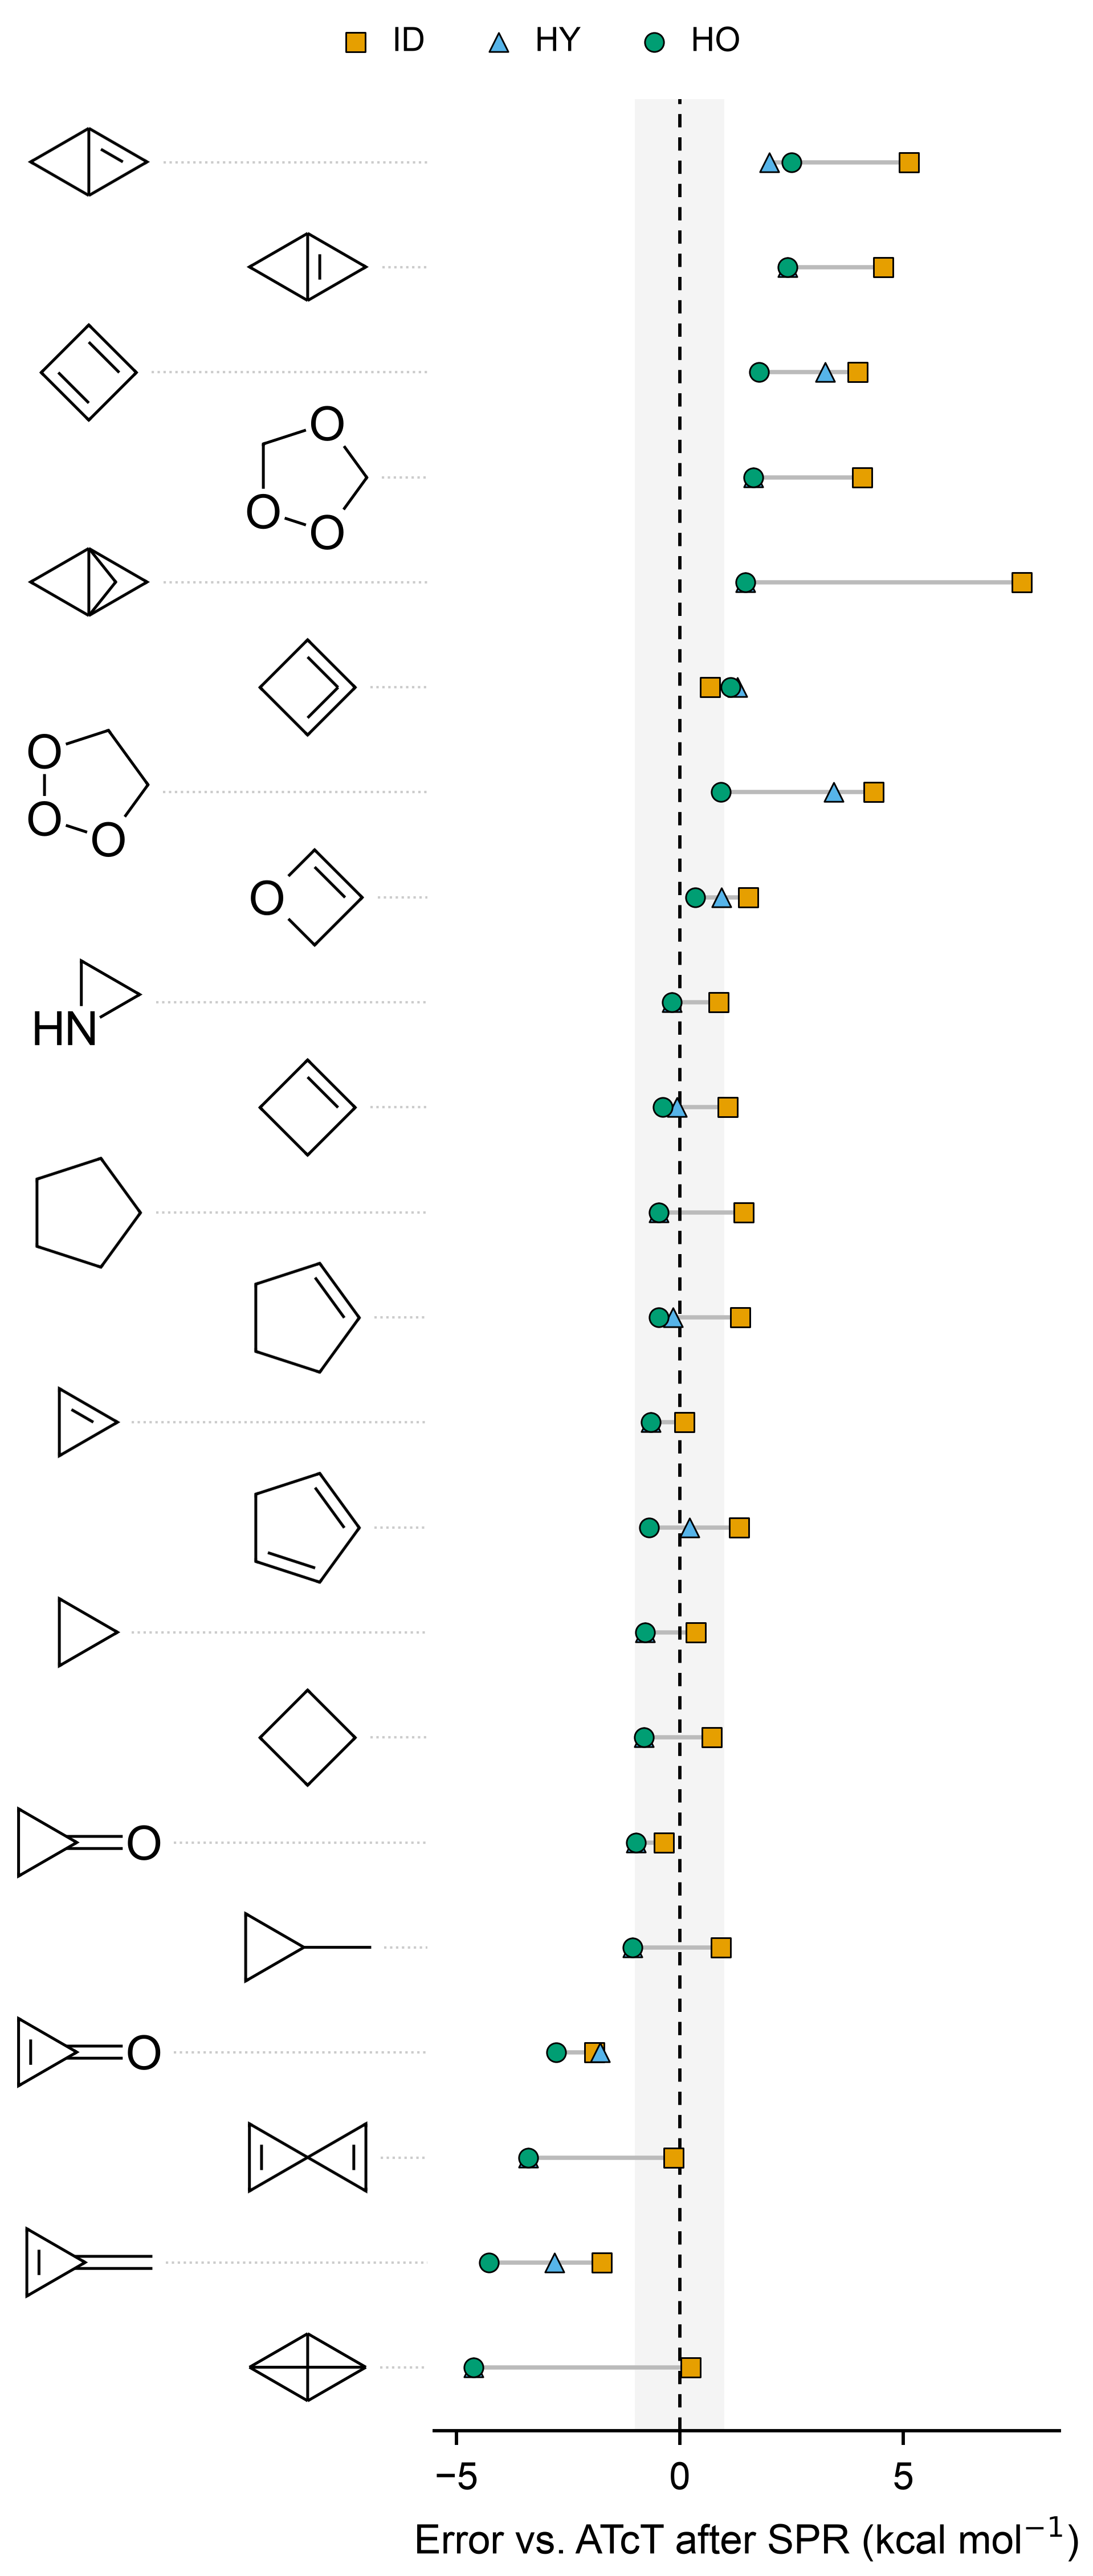

In [7]:
def fig5():
    idx = np.where(is_str)[0]
    mean = {s: np.mean([err["sp"][lv][s][idx] for lv in LEVELS], axis=0) for s in SCHEMES}
    order = np.argsort(mean["HO"])[::-1]  # largest positive error at top
    n = len(order)
    rowh, left, right, bottom, top = 0.31, 1.34, 0.08, 0.42, 0.30
    W, H = COL1, rowh * n + bottom + top
    fig = plt.figure(figsize=(W, H))
    # structures alternate between two columns so that each can be about two rows tall
    bw, bh, xc = 0.60, 0.56, (0.33, 0.97)
    smis = [SMILES[mol_order[idx[o]]] for o in order]
    sc = min(ACS, common_scale(smis, bw, bh, label_ends=False))
    ax = fig.add_axes([left / W, bottom / H, (W - left - right) / W, (H - bottom - top) / H])
    y = np.arange(n)[::-1]
    ax.axvspan(-1, 1, color="#999999", alpha=0.10, lw=0)
    ax.axvline(0, color="black", lw=0.7, ls=(0, (4, 3)))
    for yi, o in zip(y, order):
        vals = [mean[s][o] for s in SCHEMES]
        ax.plot([min(vals), max(vals)], [yi, yi], color="#BBBBBB", lw=0.9, zorder=1)
    for s, mk in zip(SCHEMES, ("s", "^", "o")):
        ax.scatter([mean[s][o] for o in order], y, marker=mk, s=16, color=COL[s], edgecolor="black", lw=0.35, zorder=3, label=NAME[s])
    ax.set_yticks([]); ax.set_ylim(-0.6, n - 0.4); ax.set_xlim(-5.5, 8.5)
    ax.set_xlabel("Error vs. ATcT after SPR (kcal mol$^{-1}$)")
    ax.spines["left"].set_visible(False)
    fig.legend(handles=ax.get_legend_handles_labels()[0], labels=SCHEMES, loc="upper center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 1.0), handletextpad=0.1, columnspacing=1.2, fontsize=7)
    ylo, yhi = ax.get_ylim()
    for k, (yi, o) in enumerate(zip(y, order)):
        cy = bottom + (yi - ylo) / (yhi - ylo) * (H - bottom - top)
        cx = xc[k % 2]
        a = place_mol(fig, smis[k], cx, cy, bw, bh, scale=sc, label_ends=False)
        x1 = a.get_position().x1 * W + 0.03
        fig.add_artist(plt.Line2D([x1 / W, (left - 0.02) / W], [cy / H] * 2, color="#CCCCCC", lw=0.5, ls=(0, (1, 1.5))))
    save(fig, "fig5_strained")


fig5()
show("fig5_strained")

## Figure 6: scalability

wrote fig6_scalability


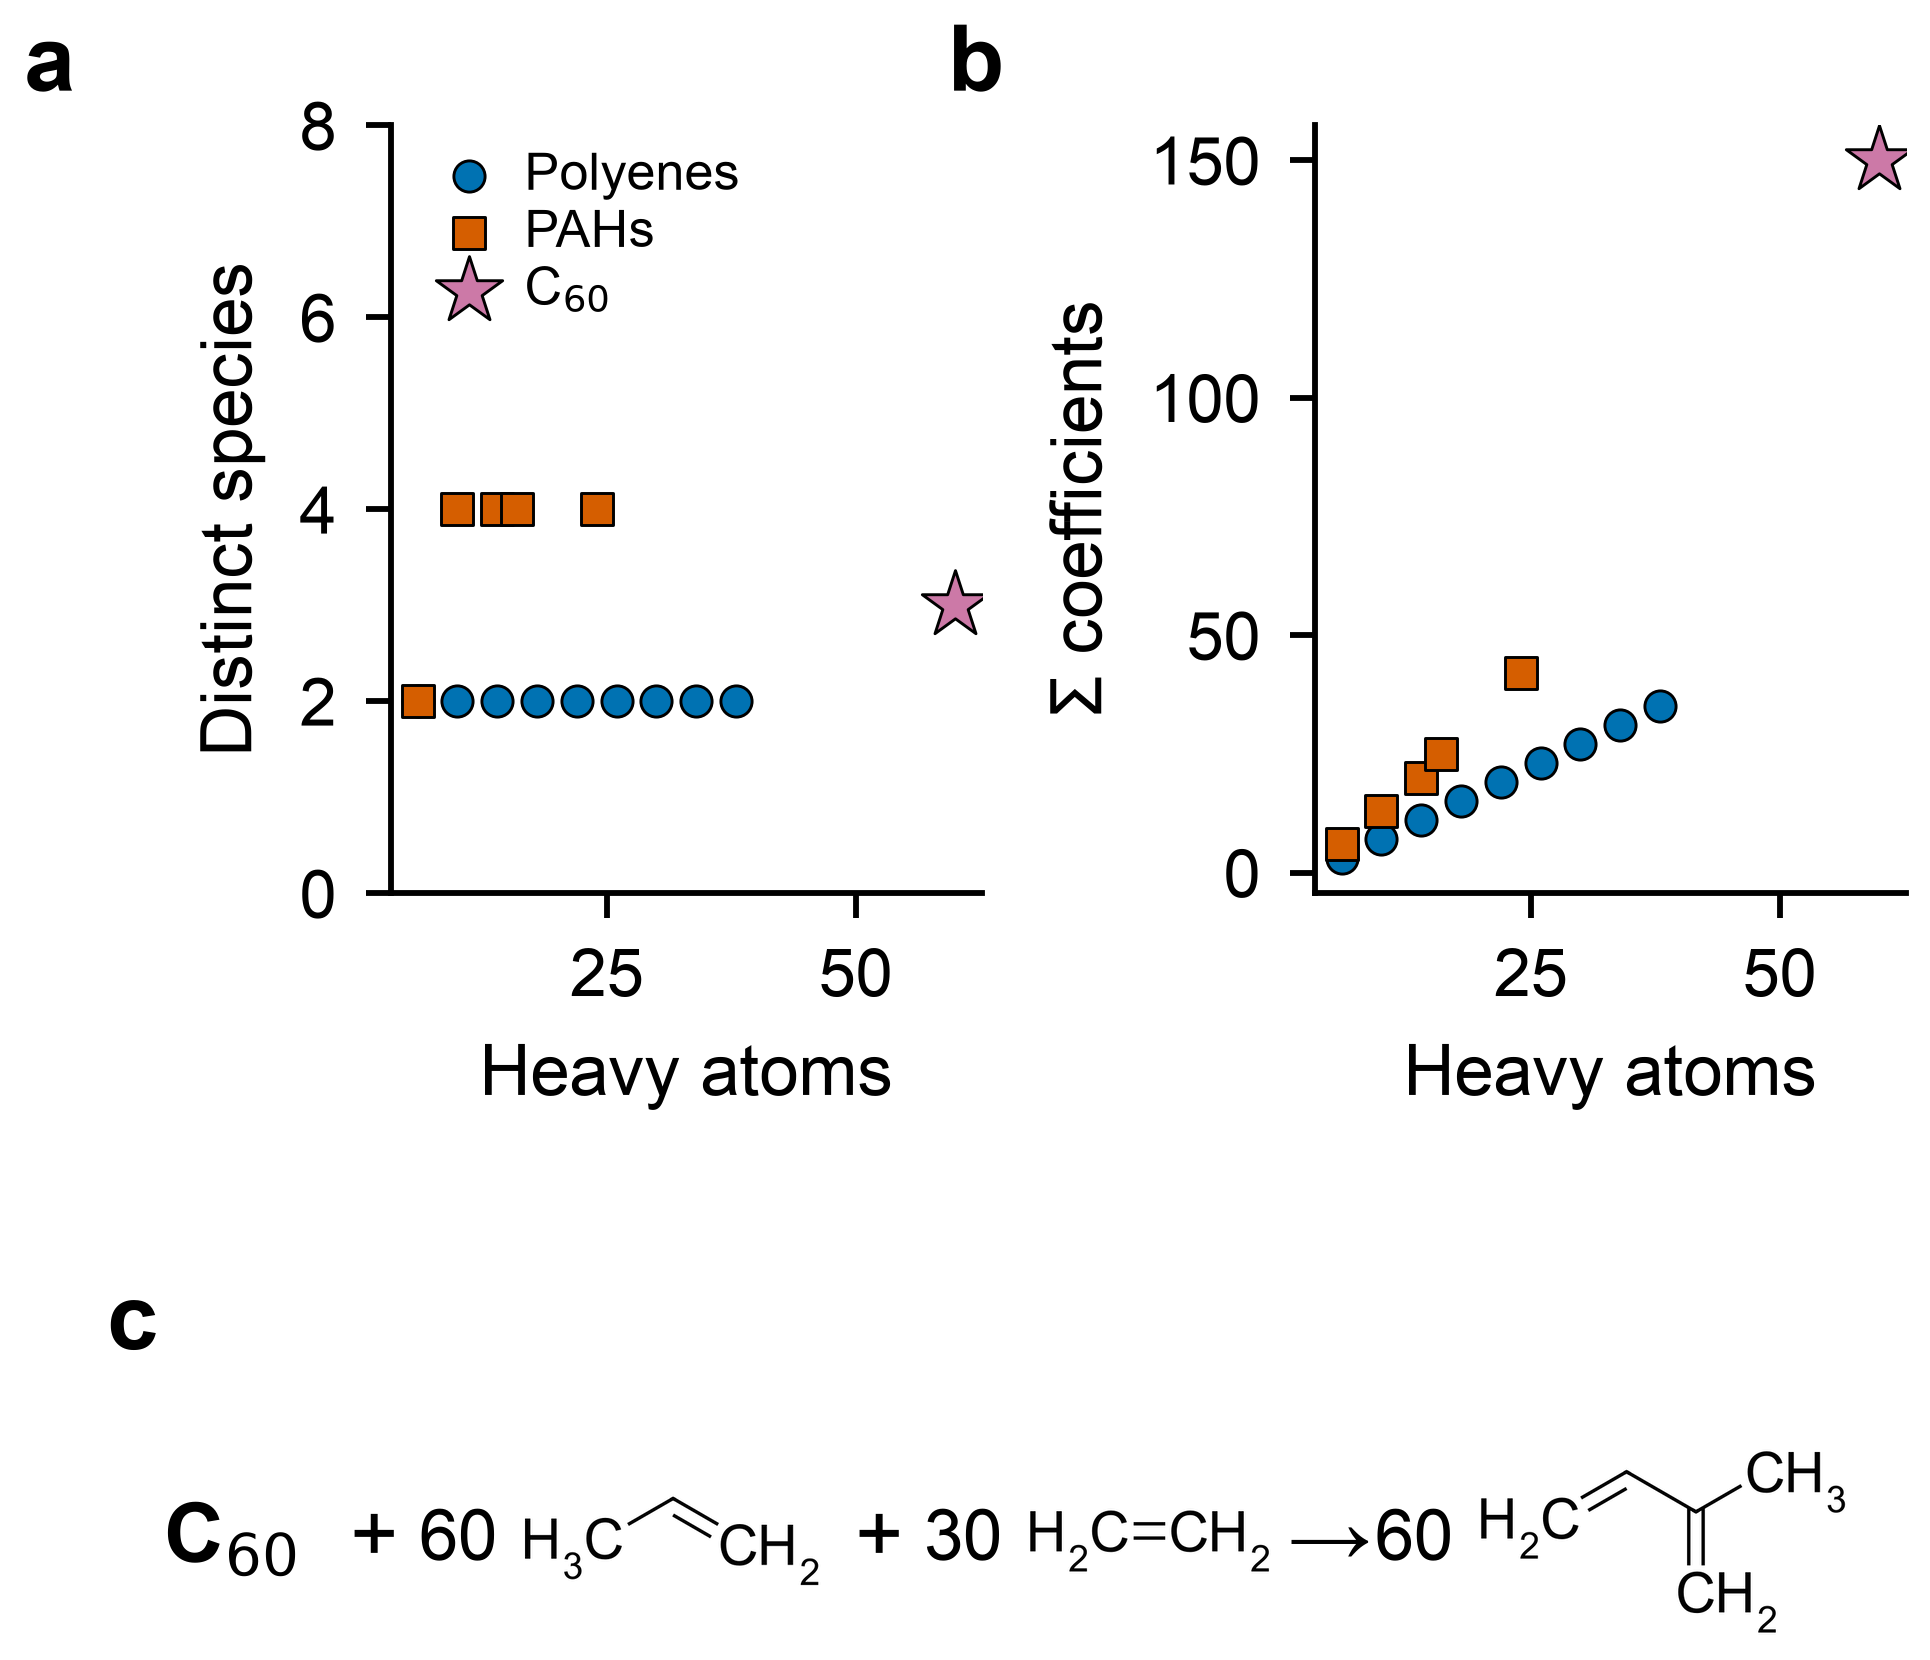

In [8]:
def fig6():
    data = list(csv.DictReader(open("data/scaling.csv")))
    W, H = COL1 - 0.17, 3.2
    fig = plt.figure(figsize=(W, H))
    axa = fig.add_axes([0.16, 0.50, 0.32, 0.40]); axb = fig.add_axes([0.66, 0.50, 0.32, 0.40])
    mk = {"polyene": ("o", "#0072B2"), "PAH": ("s", "#D55E00"), "fullerene": ("*", "#CC79A7")}
    lab = {"polyene": "Polyenes", "PAH": "PAHs", "fullerene": "C$_{60}$"}
    for fam in ("polyene", "PAH", "fullerene"):
        d = [r for r in data if r["family"] == fam]
        x = [int(r["heavy_atoms"]) for r in d]
        m, c = mk[fam]
        ms = 70 if fam == "fullerene" else 14
        axa.scatter(x, [int(r["distinct_refs"]) for r in d], marker=m, s=ms, color=c, edgecolor="black", lw=0.35, label=lab[fam], zorder=3)
        axb.scatter(x, [int(r["total_ref_molecules"]) for r in d], marker=m, s=ms, color=c, edgecolor="black", lw=0.35, zorder=3)
    axa.set_ylim(0, 8); axa.set_yticks([0, 2, 4, 6, 8])
    axa.set_xlabel("Heavy atoms"); axa.set_ylabel("Distinct species")
    axa.legend(frameon=False, loc="upper left", fontsize=6.3, handletextpad=0.05, labelspacing=0.15, borderpad=0)
    axb.set_xlabel("Heavy atoms"); axb.set_ylabel("Σ coefficients")
    panel(axa, "a", -0.62, 1.02); panel(axb, "b", -0.62, 1.02)
    y0 = 0.52
    fig.text(0.02 / W, (y0 + 0.36) / H, "c", fontsize=11, fontweight="bold", va="center")
    smis = ["CC=C", "C=C", "C=CC(=C)C"]
    imgs = [crop(mol_png(s)) for s in smis]
    sc = min(ACS, 0.55 / max(i.shape[0] for i in imgs), 0.62 / max(i.shape[1] for i in imgs))
    x = 0.08
    fig.text((x + 0.15) / W, y0 / H, "C$_{60}$", ha="center", va="center", fontsize=10, fontweight="bold"); x += 0.32
    for sym, img, smi, cnt in (("+", imgs[0], smis[0], "60"), ("+", imgs[1], smis[1], "30"), ("→", imgs[2], smis[2], "60")):
        fig.text((x + 0.065) / W, y0 / H, sym, ha="center", va="center", fontsize=10); x += 0.13
        fig.text((x + 0.01) / W, y0 / H, cnt, ha="left", va="center", fontsize=8.5); x += 0.18
        iw = img.shape[1] * sc
        place_mol(fig, smi, x + iw / 2, y0, iw, img.shape[0] * sc, scale=sc); x += iw + 0.03
    save(fig, "fig6_scalability")


fig6()
show("fig6_scalability")

## Figures S2 and S3: wildcard fragment libraries (SI)

wrote figS2_wildcard_libraries
wrote figS3_wildcard_library_homodesmotic


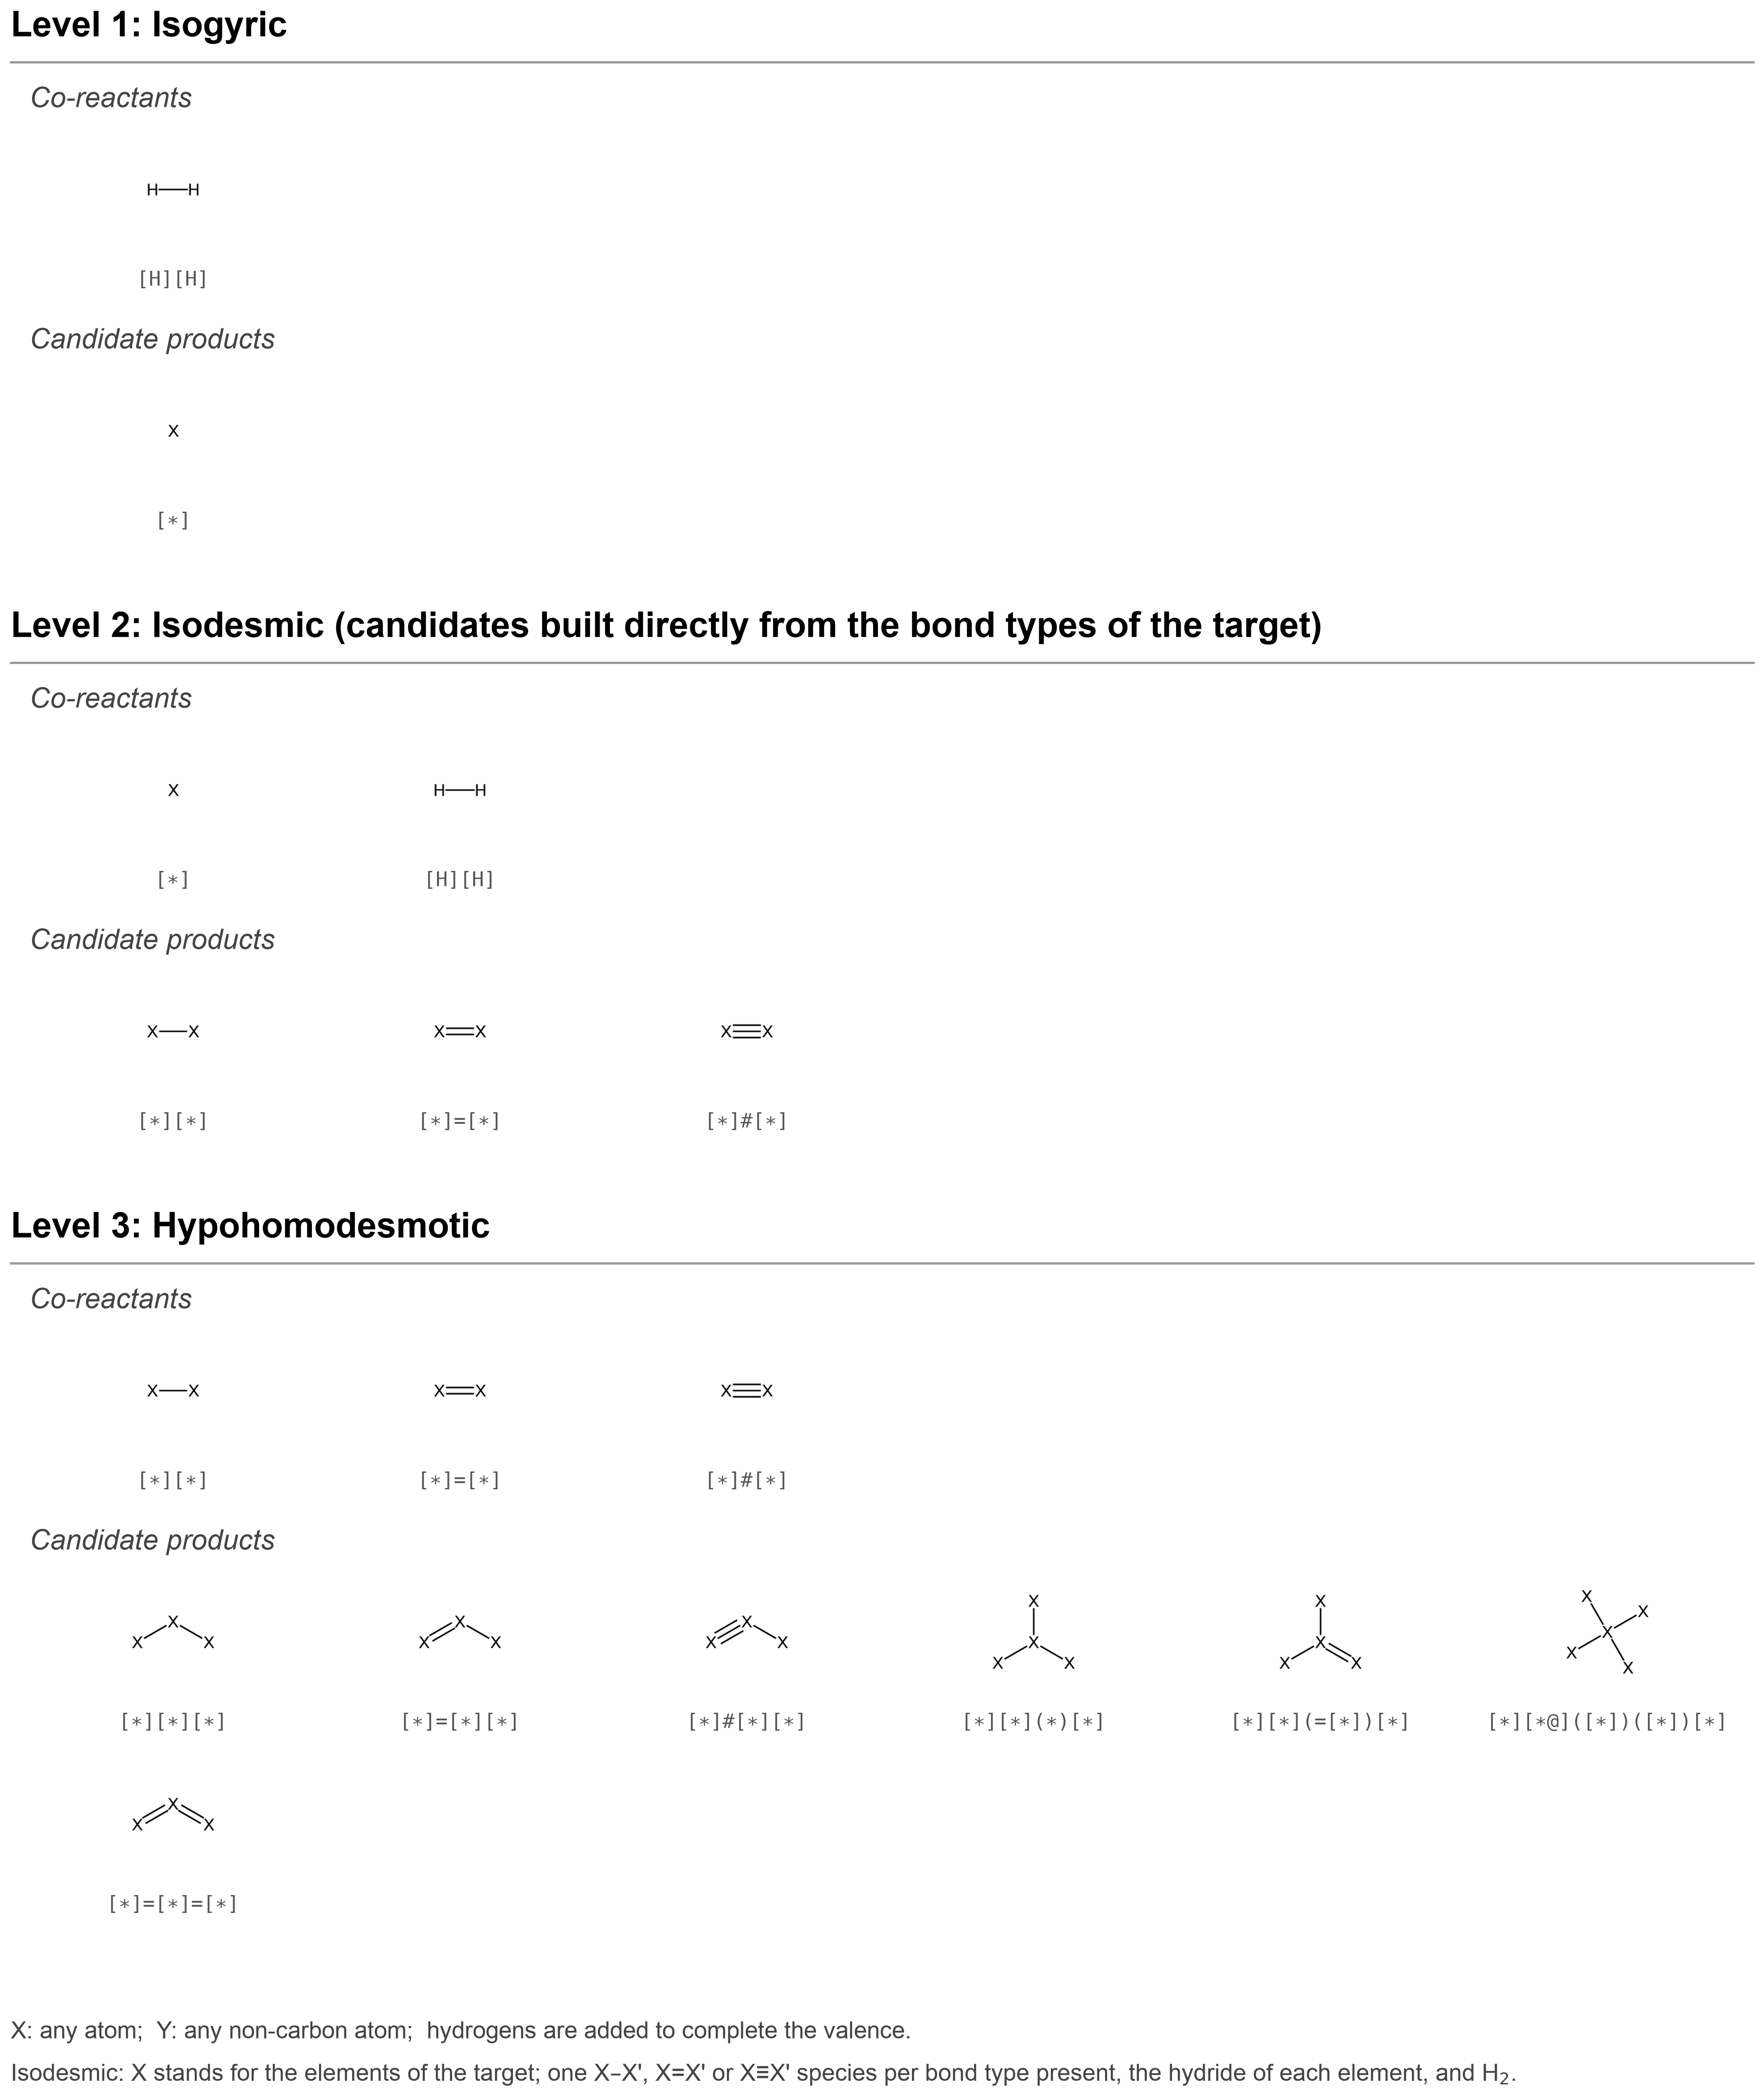

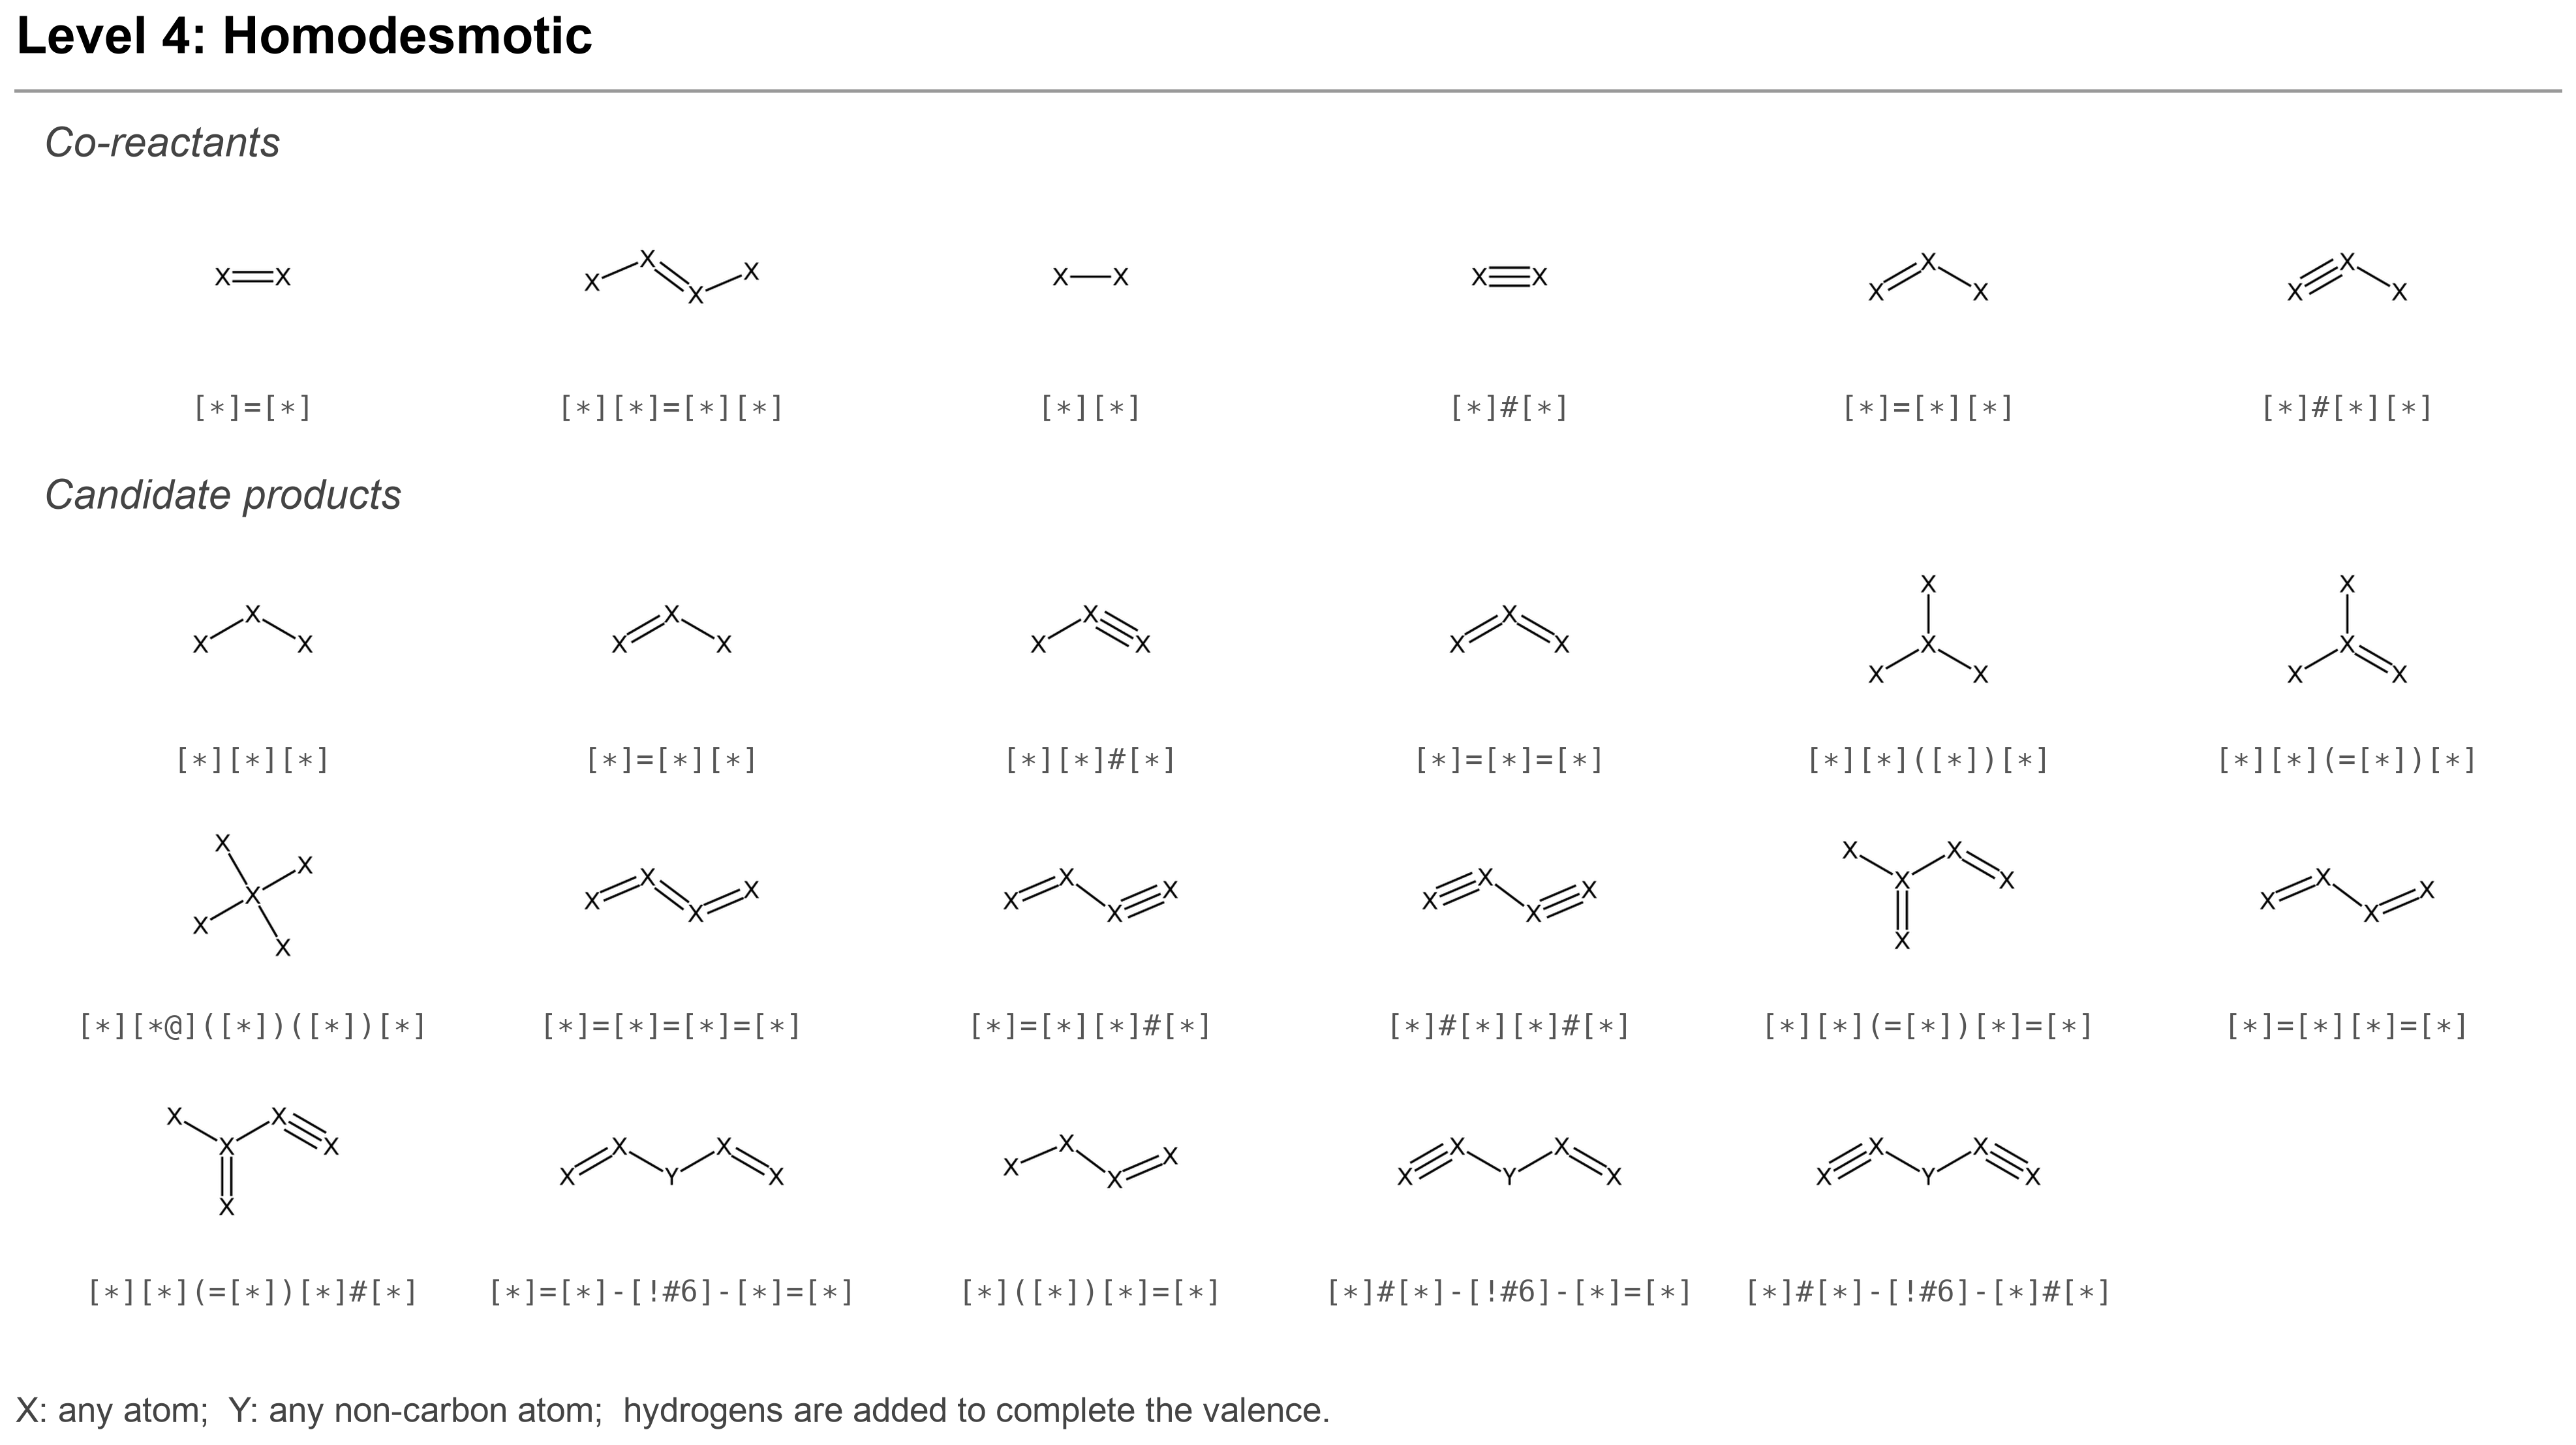

In [9]:
def frag_png(pattern, syntax, w=520, h=300):
    """A wildcard pattern drawn as an explicit Kekule structure: every atom is a letter, bonds are lines.
    X = any atom, Y = any non-carbon atom ([!#6]); hydrogens are not shown (they are added to complete valence)."""
    from rdkit.Chem import rdDepictor

    m = Chem.MolFromSmarts(pattern) if syntax == "SMARTS" else Chem.MolFromSmiles(pattern)
    if syntax != "SMARTS":
        Chem.RemoveStereochemistry(m)
    m.UpdatePropertyCache(strict=False)
    Chem.FastFindRings(m)
    rdDepictor.SetPreferCoordGen(False)
    rdDepictor.Compute2DCoords(m)
    d = rdMolDraw2D.MolDraw2DCairo(w, h)
    o = d.drawOptions()
    o.clearBackground = False
    o.bondLineWidth = 2.4
    o.padding = 0.12
    o.fixedBondLength = 42
    o.useBWAtomPalette()
    for a in m.GetAtoms():
        sm = a.GetSmarts() if syntax == "SMARTS" else ""
        if a.GetAtomicNum() == 0:
            o.atomLabels[a.GetIdx()] = "Y" if "!#6" in sm else "X"
        else:  # e.g. the H atoms of H2: label every atom explicitly
            o.atomLabels[a.GetIdx()] = a.GetSymbol()
    d.DrawMolecule(m)
    d.FinishDrawing()
    return np.array(Image.open(io.BytesIO(d.GetDrawingText())).convert("RGBA"))


def fig_wildcards(keep, outname, isodesmic_note):
    rows = list(csv.DictReader(open("data/wildcard_libraries.csv", encoding="utf-8")))
    levels = [l for l in [(1, "Isogyric"), (2, "Isodesmic (candidates built directly from the bond types of the target)"), (3, "Hypohomodesmotic"), (4, "Homodesmotic")] if l[0] in keep]
    rows = [r for r in rows if int(r["level"]) in keep]
    ncol, cw, ch, W = 6, 1.07, 0.68, 6.6
    blocks = []  # (level title, [(role, [rows...])])
    for lv, name in levels:
        sel = [r for r in rows if int(r["level"]) == lv]
        blocks.append((lv, name, [("Co-reactants", [r for r in sel if r["role"] == "reactants"]),
                                  ("Candidate products", [r for r in sel if r["role"] == "products"])]))
    H = 0.62 if isodesmic_note else 0.45  # room for the legend
    for _, _, groups in blocks:
        H += 0.32
        for _, items in groups:
            H += 0.22 + math.ceil(len(items) / ncol) * ch
        H += 0.12
    imgs = {(r["level"], r["role"], r["pattern"]): frag_png(r["pattern"], r["syntax"]) for r in rows}
    sc = min(min(0.9 * cw / crop(i).shape[1], 0.50 * ch / crop(i).shape[0]) for i in imgs.values())
    fig = plt.figure(figsize=(W, H))
    y = H - 0.1
    for lv, name, groups in blocks:  # noqa: E501
        fig.text(0.05 / W, (y - 0.14) / H, f"Level {lv}: {name}", fontsize=9.5, fontweight="bold", va="center")
        fig.add_artist(plt.Line2D([0.05 / W, (W - 0.05) / W], [(y - 0.27) / H] * 2, color="#999999", lw=0.6, transform=fig.transFigure))
        y -= 0.32
        for gname, items in groups:
            fig.text(0.12 / W, (y - 0.09) / H, gname, fontsize=7.5, style="italic", color="#444444", va="center")
            y -= 0.22
            for i, r in enumerate(items):
                col, row = i % ncol, i // ncol
                cx = 0.12 + (col + 0.5) * cw
                cy = y - row * ch - 0.30 * ch
                img = crop(imgs[(r["level"], r["role"], r["pattern"])])
                iw, ih = img.shape[1] * sc, img.shape[0] * sc
                ax = fig.add_axes([(cx - iw / 2) / W, (cy - ih / 2) / H, iw / W, ih / H])
                ax.imshow(img, aspect="equal", interpolation="lanczos")
                ax.axis("off")
                fig.text(cx / W, (y - row * ch - 0.80 * ch) / H, r["pattern"].replace("*", "\u2217"), fontsize=5.4, family="DejaVu Sans Mono",
                         ha="center", va="center", color="#555555")
            y -= math.ceil(len(items) / ncol) * ch
        y -= 0.12
    fig.text(0.05 / W, 0.26 / H, "X: any atom;  Y: any non-carbon atom;  hydrogens are added to complete the valence.", fontsize=6.4, color="#444444", va="bottom")
    if isodesmic_note:
        fig.text(0.05 / W, 0.10 / H, "Isodesmic: X stands for the elements of the target; one X–X', X=X' or X≡X' species per bond type present, the hydride of each element, and H$_2$.",
                 fontsize=6.4, color="#444444", va="bottom")
    save(fig, outname)


fig_wildcards((1, 2, 3), "figS2_wildcard_libraries", True)
fig_wildcards((4,), "figS3_wildcard_library_homodesmotic", False)
show("figS2_wildcard_libraries")
show("figS3_wildcard_library_homodesmotic")